<style>
    /* 1. Самый надежный способ для кода - бить по тегу pre внутри input-блоков */
    div.input_area pre, 
    div.highlight pre, 
    div.highlight,
    pre {
        font-size: 7pt !important;
        line-height: 120% !important;
    }

    /* 2. Для текстовых ячеек (Markdown) */
    div.text_cell_render {
        font-size: 7pt !important;
    }

    /* 3. Для вывода (Output) - чтобы он не был гигантским по сравнению с кодом */
    div.output_area pre, 
    div.output_subarea {
        font-size: 7pt !important;
    }

    /* 4. Уменьшаем "In [ ]:" и "Out [ ]:" слева, чтобы они не сползали */
    div.prompt {
        font-size: 7pt !important;
        min-width: 4ex !important; /* сужаем колонку с номерами */
    }
</style>


# Linear Superposition in LLMs: Mechanistic Analysis

**Motivation:** We performed an experiment where we passed texts A and B through the LLM like this: LLM(A+B). 
Yes, by simply token-wise adding/averaging the embeddings for two separate texts. And we observed that even **before** any fine-tuning we have $LLM(A+B) ≈ LLM(A)+LLM(B)$. We measured this by ranking the positions of the top-1 tokens from the clean single-stream run of both texts in the superposed-stream output distribution.

Surprisingly, we've found:

```
--- METRICS AGAINST VANILLA MODEL'S PREDICTION ---
VANILLA MODEL'S TOP TOKEN RANK (on non-missed vanilla targets):
  Text A: 10.14 ± 2.21
  Text B: 10.19 ± 2.03
  Average: 10.15 ± 1.39
```

Which is quite peculiar (the 10th position is quite low, considering that the Vocabulary size is often >50k), and it means that LLMs are somewhat linear.

**In this notebook, we aim to investigate why Attention doesn't destroy the superposition of embeddings.**

*Core Question:* When we feed $X_{mix} = \text{Norm}(Embed(A) + Embed(B))$ into a transformer, why does Attention (with its nonlinear Softmax) not completely destroy the superposition?

**For our analysis, we will assume that:**

For any layer $\ell$, we assume the linearity of Q and K projections:
$$ Q_{mix}^{(\ell)} \approx Q_{A,clean}^{(\ell)} + Q_{B,clean}^{(\ell)} $$
$$ K_{mix}^{(\ell)} \approx K_{A,clean}^{(\ell)} + K_{B,clean}^{(\ell)} $$
This allows us to decompose the attention score:
$$ \begin{align*} \text{Score}_{mix}^{(\ell)} &\approx (Q_{A,clean}^{(\ell)} + Q_{B,clean}^{(\ell)})(K_{A,clean}^{(\ell)} + K_{B,clean}^{(\ell)})^T \\ &\approx \underbrace{Q_{A,clean}^{(\ell)} (K_{A,clean}^{(\ell)})^T}_{\text{Signal A}} + \underbrace{Q_{B,clean}^{(\ell)} (K_{B,clean}^{(\ell)})^T}_{\text{Signal B}} + \underbrace{Q_{A,clean}^{(\ell)} (K_{B,clean}^{(\ell)})^T}_{\text{Cross-Talk}} + \underbrace{Q_{B,clean}^{(\ell)} (K_{A,clean}^{(\ell)})^T}_{\text{Cross-Talk}} \end{align*} $$

$$\text{SSR}_{head}^{(\ell)} = \frac{\| Q_{mix}^{(\ell)} (K_{A,clean}^{(\ell)})^T \|_F}{\| Q_{mix}^{(\ell)} (K_{B,clean}^{(\ell)})^T \|_F}$$

**Experiments:**
1. *Stream Selectivity Ratio (SSR)* in Attention Scores
2. *"Ghost Context" Analysis* (Leakage via Values) 
3. *Attention Pattern Overlap* vs. Quality degradation


In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer
from typing import Dict, List, Tuple, Optional
from dataclasses import dataclass
from tqdm.auto import tqdm
import seaborn as sns
from collections import defaultdict
from datasets import load_dataset
import json
import random

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


## Configuration

Choose between baseline model or fine-tuned dual-stream model.


In [ ]:
# ============== CONFIGURATION ==============
# Choose model size (smaller for testing, larger for real analysis)
MODEL_NAME = "EleutherAI/pythia-6.9b"  # Options: pythia-410m, pythia-1.4b, pythia-6.9b

# Set to True to use a fine-tuned DualStreamLLM checkpoint
USE_FINETUNED = False
CHECKPOINT_PATH = None  # e.g., "./checkpoints/run_xxx/checkpoint_step_10000.pt"

# FineWeb-Edu dataset parameters
NUM_TEXT_PAIRS = 100  # Number of text pairs to analyze
SEED = 42  # Random seed for reproducibility
MIN_TEXT_LENGTH = 100  # Minimum text length in characters

# Test texts for single-pair demo (used if not loading from dataset)
TEXT_A = "The capital of France is Paris, which is known for the Eiffel Tower"
TEXT_B = "Machine learning algorithms can process large amounts of data efficiently"

# Analysis parameters
MAX_LENGTH = 64
USE_DATASET = True  # If True, load from FineWeb-Edu; if False, use demo texts above

# Results saving
RESULTS_FILE = "mechanistic_analysis_results.json"


In [ ]:
# Load model and tokenizer
print(f"Loading model: {MODEL_NAME}")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    output_attentions=True,
    output_hidden_states=True,
)
model.eval()

# Get model config
config = model.config
num_layers = config.num_hidden_layers
num_heads = config.num_attention_heads
hidden_size = config.hidden_size
head_dim = hidden_size // num_heads

print(f"Model loaded: {num_layers} layers, {num_heads} heads, hidden_size={hidden_size}")


In [ ]:
# Optional: Load fine-tuned DualStreamLLM
dual_stream_model = None

if USE_FINETUNED and CHECKPOINT_PATH:
    from model import DualStreamLLM
    
    print(f"Loading fine-tuned model from: {CHECKPOINT_PATH}")
    dual_stream_model = DualStreamLLM(
        model_name=MODEL_NAME,
        freeze_backbone=True,
        objective='separate',
        shared_embeddings=False,
    )
    
    checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu')
    dual_stream_model.load_state_dict(checkpoint['model_state_dict'])
    dual_stream_model = dual_stream_model.to(device)
    dual_stream_model.eval()
    print("Fine-tuned model loaded!")
else:
    print("Using baseline (non-finetuned) model for analysis")


In [ ]:
def compute_off_diagonal_overlap(
    attn_A: torch.Tensor,  # [batch, heads, seq, seq]
    attn_B: torch.Tensor,
    zero_diagonal: bool = True,
    zero_first_column: bool = True,
    method: str = 'cosine'
) -> Dict[str, torch.Tensor]:
    """
    Compute overlap between attention patterns from A and B,
    EXCLUDING trivial components (diagonal and first token / attention sink).
    
    Why this matters:
    - Diagonal attention (token attending to itself) is trivial and universal
    - First token attention (sink) is a known artifact
    - These inflate overlap artificially, hiding real cross-talk
    - We care about INDUCTION patterns (looking back into history)
    
    Args:
        attn_A, attn_B: Attention weights [batch, heads, seq, seq]
        zero_diagonal: If True, set diagonal attention to 0 before comparison
        zero_first_column: If True, set attention to first token to 0
        method: 'cosine' or 'iou'
    
    Returns:
        Dictionary with overlap metrics
    """
    batch, n_heads, seq_q, seq_k = attn_A.shape
    
    # Clone to avoid modifying original
    attn_A_clean = attn_A.clone().float()
    attn_B_clean = attn_B.clone().float()
    
    if zero_diagonal:
        # Zero out diagonal (token attending to itself)
        # For causal attention, diagonal exists where i <= j
        for i in range(min(seq_q, seq_k)):
            attn_A_clean[:, :, i, i] = 0
            attn_B_clean[:, :, i, i] = 0
    
    if zero_first_column:
        # Zero out attention to first token (attention sink)
        attn_A_clean[:, :, :, 0] = 0
        attn_B_clean[:, :, :, 0] = 0
    
    # Re-normalize after zeroing (so we compare proper distributions)
    attn_A_clean = attn_A_clean / (attn_A_clean.sum(dim=-1, keepdim=True) + 1e-10)
    attn_B_clean = attn_B_clean / (attn_B_clean.sum(dim=-1, keepdim=True) + 1e-10)
    
    if method == 'cosine':
        # Normalize for cosine similarity
        attn_A_norm = F.normalize(attn_A_clean, p=2, dim=-1)
        attn_B_norm = F.normalize(attn_B_clean, p=2, dim=-1)
        
        # Cosine similarity: sum(a*b)
        cosine_sim = (attn_A_norm * attn_B_norm).sum(dim=-1)  # [batch, heads, seq_q]
        
        return {
            'per_position': cosine_sim,
            'mean_per_head': cosine_sim.mean(dim=-1),  # [batch, heads]
            'overall_mean': cosine_sim.mean().item()
        }
    
    elif method == 'iou':
        # Intersection over Union for top-k attended positions (excluding diagonal/first)
        top_k = 5
        
        _, top_A = torch.topk(attn_A_clean, top_k, dim=-1)
        _, top_B = torch.topk(attn_B_clean, top_k, dim=-1)
        
        iou_scores = []
        for b in range(batch):
            for h in range(n_heads):
                for q in range(seq_q):
                    set_A = set(top_A[b, h, q].tolist())
                    set_B = set(top_B[b, h, q].tolist())
                    intersection = len(set_A & set_B)
                    union = len(set_A | set_B)
                    iou_scores.append(intersection / union if union > 0 else 0)
        
        return {
            'iou_scores': iou_scores,
            'mean_iou': np.mean(iou_scores)
        }
    
    else:
        raise ValueError(f"Unknown method: {method}")


# Also keep the original for comparison
def compute_attention_overlap_original(
    attn_A: torch.Tensor,
    attn_B: torch.Tensor,
) -> float:
    """Original overlap (including diagonal) for comparison."""
    attn_A_norm = F.normalize(attn_A.float(), p=2, dim=-1)
    attn_B_norm = F.normalize(attn_B.float(), p=2, dim=-1)
    return (attn_A_norm * attn_B_norm).sum(dim=-1).mean().item()


def compute_prediction_rank(
    logits: torch.Tensor,  # [batch, seq, vocab]
    target_ids: torch.Tensor,  # [batch, seq]
    position: int = -2
) -> List[int]:
    """
    Compute rank of target token in prediction distribution.
    Rank 1 = correct token is top prediction.
    """
    batch = logits.shape[0]
    ranks = []
    
    for b in range(batch):
        pos_logits = logits[b, position, :]
        target_id = target_ids[b, position + 1].item()  # Next token prediction
        
        # Sort logits descending
        sorted_indices = torch.argsort(pos_logits, descending=True)
        rank = (sorted_indices == target_id).nonzero(as_tuple=True)[0].item() + 1
        ranks.append(rank)
    
    return ranks


## Load Text Pairs from FineWeb-Edu

Load and prepare text pairs for multi-sample analysis.

In [ ]:
if USE_DATASET:
    print(f"Loading {NUM_TEXT_PAIRS} text pairs from FineWeb-Edu...")
    random.seed(SEED)
    np.random.seed(SEED)
    
    # Load FineWeb-Edu dataset (sample subset)
    # Using streaming to avoid loading the entire dataset
    dataset = load_dataset("HuggingFaceFW/fineweb-edu", name="sample-10BT", split="train", streaming=True)
    
    # Collect texts that meet minimum length requirement
    texts_pool = []
    for sample in dataset:
        text = sample['text'].strip()
        if len(text) >= MIN_TEXT_LENGTH:
            texts_pool.append(text)
        
        # Stop when we have enough texts (need 2x pairs)
        if len(texts_pool) >= NUM_TEXT_PAIRS * 2:
            break
    
    print(f"Collected {len(texts_pool)} texts from FineWeb-Edu")
    
    # Create pairs
    text_pairs = []
    for i in range(0, len(texts_pool) - 1, 2):
        if len(text_pairs) >= NUM_TEXT_PAIRS:
            break
        text_pairs.append((texts_pool[i], texts_pool[i + 1]))
    
    print(f"Created {len(text_pairs)} text pairs")
    print(f"\nExample pair:")
    print(f"  Text A: {text_pairs[0][0][:100]}...")
    print(f"  Text B: {text_pairs[0][1][:100]}...")
else:
    # Use demo texts
    print("Using demo text pair from configuration")
    text_pairs = [(TEXT_A, TEXT_B)]
    print(f"Text A: {TEXT_A}")
    print(f"Text B: {TEXT_B}")

## Utility Functions

Helper functions for extracting internal states and computing metrics.


In [ ]:
@dataclass
class AttentionInternals:
    """Stores Q, K, V and attention weights from a forward pass."""
    queries: List[torch.Tensor]  # [num_layers] each [batch, num_heads, seq_len, head_dim]
    keys: List[torch.Tensor]
    values: List[torch.Tensor]
    attention_weights: List[torch.Tensor]  # [num_layers] each [batch, num_heads, seq_len, seq_len]
    hidden_states: List[torch.Tensor]  # [num_layers+1] each [batch, seq_len, hidden_dim]
    logits: torch.Tensor  # [batch, seq_len, vocab_size]


@dataclass 
class ForwardPassResult:
    """Complete result of a forward pass with all internals."""
    input_ids: torch.Tensor
    attention_mask: torch.Tensor
    internals: AttentionInternals


In [ ]:
def tokenize_text(text: str, pad_to_length: int = None) -> Tuple[torch.Tensor, torch.Tensor]:
    """Tokenize text and return input_ids and attention_mask on device.
    
    Args:
        text: Input text to tokenize
        pad_to_length: If specified, pad/truncate to this exact length
    """
    if pad_to_length is not None:
        encoded = tokenizer(
            text,
            max_length=pad_to_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
    else:
        # No padding - just tokenize
        encoded = tokenizer(
            text,
            max_length=MAX_LENGTH,
            truncation=True,
            return_tensors='pt'
        )
    return encoded['input_ids'].to(device), encoded['attention_mask'].to(device)


def tokenize_pair_to_min_length(text_a: str, text_b: str) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, int]:
    """
    Tokenize two texts and truncate BOTH to the MINIMUM length.
    This ensures every position has a true superposition (no PAD + real token).
    
    Returns:
        input_ids_A, attention_mask_A, input_ids_B, attention_mask_B, common_length
    """
    # First tokenize without padding to get actual lengths
    enc_a = tokenizer(text_a, max_length=MAX_LENGTH, truncation=True, return_tensors='pt')
    enc_b = tokenizer(text_b, max_length=MAX_LENGTH, truncation=True, return_tensors='pt')
    
    len_a = enc_a['input_ids'].shape[1]
    len_b = enc_b['input_ids'].shape[1]
    
    # Use minimum length for clean experiment
    common_length = min(len_a, len_b)
    
    # Truncate both to common length
    input_ids_A = enc_a['input_ids'][:, :common_length].to(device)
    input_ids_B = enc_b['input_ids'][:, :common_length].to(device)
    
    # Attention masks are all 1s since no padding
    attention_mask_A = torch.ones_like(input_ids_A).to(device)
    attention_mask_B = torch.ones_like(input_ids_B).to(device)
    
    return input_ids_A, attention_mask_A, input_ids_B, attention_mask_B, common_length


def get_lm_head_weights(model):
    """Get the language model head weights for logit lens."""
    if hasattr(model, 'embed_out'):
        # Pythia
        return model.embed_out.weight.detach()
    elif hasattr(model, 'lm_head'):
        return model.lm_head.weight.detach()
    else:
        raise ValueError("Cannot find LM head")

In [ ]:
def create_mixed_embeddings(model, input_ids_A, input_ids_B):
    """
    Create mixed embeddings: Norm(Embed(A) + Embed(B))
    Using dynamic rescaling to preserve norm.
    """
    # Get embedding layer
    if hasattr(model, 'gpt_neox'):
        embed_layer = model.gpt_neox.embed_in
    elif hasattr(model, 'model') and hasattr(model.model, 'embed_tokens'):
        embed_layer = model.model.embed_tokens
    elif hasattr(model, 'transformer'):
        embed_layer = model.transformer.wte
    else:
        raise ValueError("Unknown model architecture")
    
    with torch.no_grad():
        embed_A = embed_layer(input_ids_A)  # [batch, seq, hidden]
        embed_B = embed_layer(input_ids_B)
        
        # Sum embeddings
        sum_embeds = embed_A + embed_B
        
        # Dynamic rescaling (same as in model.py)
        norm_A = torch.norm(embed_A, p=2, dim=-1, keepdim=True)
        norm_B = torch.norm(embed_B, p=2, dim=-1, keepdim=True)
        norm_sum = torch.norm(sum_embeds, p=2, dim=-1, keepdim=True)
        
        target_norm = (norm_A + norm_B) / 2.0
        scale_factor = target_norm / (norm_sum + 1e-6)
        
        mixed_embeds = sum_embeds * scale_factor
    
    return mixed_embeds, embed_A, embed_B


def forward_with_embeddings(model, inputs_embeds, attention_mask):
    """Run forward pass with custom embeddings instead of input_ids."""
    queries = []
    keys = []
    values = []
    handles = []
    
    attention_layers = get_attention_layers(model)
    
    def make_qkv_hook(layer_idx):
        def hook(module, input, output):
            hidden_states = input[0]
            
            if hasattr(module, 'query_key_value'):
                qkv = module.query_key_value(hidden_states)
                batch_size, seq_len, _ = qkv.shape
                qkv = qkv.view(batch_size, seq_len, num_heads, 3, head_dim)
                q = qkv[:, :, :, 0, :].transpose(1, 2)
                k = qkv[:, :, :, 1, :].transpose(1, 2)
                v = qkv[:, :, :, 2, :].transpose(1, 2)
            elif hasattr(module, 'q_proj'):
                q = module.q_proj(hidden_states)
                k = module.k_proj(hidden_states)
                v = module.v_proj(hidden_states)
                batch_size, seq_len, _ = q.shape
                q = q.view(batch_size, seq_len, num_heads, head_dim).transpose(1, 2)
                k = k.view(batch_size, seq_len, num_heads, head_dim).transpose(1, 2)
                v = v.view(batch_size, seq_len, num_heads, head_dim).transpose(1, 2)
            else:
                raise ValueError("Unknown attention module structure")
            
            queries.append(q.detach().cpu())
            keys.append(k.detach().cpu())
            values.append(v.detach().cpu())
        return hook
    
    for layer_idx, attn_layer in enumerate(attention_layers):
        handle = attn_layer.register_forward_hook(make_qkv_hook(layer_idx))
        handles.append(handle)
    
    with torch.no_grad():
        outputs = model(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            output_attentions=True,
            output_hidden_states=True,
            return_dict=True
        )
    
    for handle in handles:
        handle.remove()
    
    attention_weights = [attn.detach().cpu() for attn in outputs.attentions]
    hidden_states = [h.detach().cpu() for h in outputs.hidden_states]
    logits = outputs.logits.detach().cpu()
    
    return AttentionInternals(
        queries=queries,
        keys=keys,
        values=values,
        attention_weights=attention_weights,
        hidden_states=hidden_states,
        logits=logits
    )

In [ ]:
def compute_ssr_per_head(
    Q_mix: torch.Tensor,
    K_A: torch.Tensor, 
    K_B: torch.Tensor,
    scale: float = None
) -> torch.Tensor:
    """
    Compute Stream Selectivity Ratio for EACH attention head separately.
    
    SSR_head = ||Q_mix @ K_A^T||_F / ||Q_mix @ K_B^T||_F
    """
    if scale is None:
        scale = 1.0 / np.sqrt(Q_mix.shape[-1])
    
    # Compute attention scores (before softmax)
    scores_A = torch.matmul(Q_mix.float(), K_A.float().transpose(-2, -1)) * scale
    scores_B = torch.matmul(Q_mix.float(), K_B.float().transpose(-2, -1)) * scale
    
    # Compute Frobenius norm PER HEAD
    norm_signal_A_per_head = torch.norm(scores_A[0], dim=(-2, -1))  # [heads]
    norm_signal_B_per_head = torch.norm(scores_B[0], dim=(-2, -1))  # [heads]
    
    # SSR per head (avoid division by zero)
    ssr_per_head = norm_signal_A_per_head / (norm_signal_B_per_head + 1e-10)
    
    return ssr_per_head


def compute_logit_impact(output_vector: torch.Tensor, lm_head_weights: torch.Tensor) -> Dict[str, float]:
    """
    Compute the effective impact of a vector on logits.
    
    Metric: EffectiveLogitStrength = Max(Logits) - Mean(Logits)
    """
    # Handle different input shapes
    if output_vector.dim() == 4:
        # [batch, heads, seq, head_dim] -> [batch, seq, hidden]
        batch, heads, seq, hdim = output_vector.shape
        output_vector = output_vector.transpose(1, 2).reshape(batch, seq, heads * hdim)
    
    # Project to vocabulary space
    logits = output_vector.float() @ lm_head_weights.float().T
    
    # Compute metrics per position, then average
    max_logits = logits.max(dim=-1).values
    mean_logits = logits.mean(dim=-1)
    
    # Effective strength
    effective_strength = (max_logits - mean_logits).mean().item()
    
    # Logit std
    logit_std = logits.std(dim=-1).mean().item()
    
    # Top-k concentration
    probs = F.softmax(logits, dim=-1)
    top10_prob = probs.topk(10, dim=-1).values.sum(dim=-1).mean().item()
    
    return {
        'effective_strength': effective_strength,
        'logit_std': logit_std,
        'top10_concentration': top10_prob,
        'max_logit': max_logits.mean().item(),
        'mean_logit': mean_logits.mean().item()
    }

In [ ]:
def get_attention_layers(model):
    """Get list of attention layer modules (works for Pythia/GPT-NeoX)."""
    if hasattr(model, 'gpt_neox'):
        # Pythia architecture
        return [layer.attention for layer in model.gpt_neox.layers]
    elif hasattr(model, 'model') and hasattr(model.model, 'layers'):
        # LLaMA architecture
        return [layer.self_attn for layer in model.model.layers]
    elif hasattr(model, 'transformer'):
        # GPT-2 architecture
        return [layer.attn for layer in model.transformer.h]
    else:
        raise ValueError(f"Unknown model architecture: {type(model)}")


def extract_qkv_with_hooks(model, input_ids, attention_mask):
    """
    Extract Q, K, V matrices from all layers using forward hooks.
    
    Returns:
        ForwardPassResult with all internals
    """
    queries = []
    keys = []
    values = []
    handles = []
    
    attention_layers = get_attention_layers(model)
    
    def make_qkv_hook(layer_idx):
        def hook(module, input, output):
            # For Pythia/GPT-NeoX, the attention module computes QKV internally
            # We need to recompute Q, K, V from the hidden states
            hidden_states = input[0]  # [batch, seq_len, hidden_dim]
            
            # Get the QKV projection weights
            if hasattr(module, 'query_key_value'):
                # Pythia: fused QKV projection
                qkv = module.query_key_value(hidden_states)
                # Split into Q, K, V
                # Shape: [batch, seq_len, 3 * num_heads * head_dim]
                batch_size, seq_len, _ = qkv.shape
                qkv = qkv.view(batch_size, seq_len, num_heads, 3, head_dim)
                q = qkv[:, :, :, 0, :].transpose(1, 2)  # [batch, heads, seq, head_dim]
                k = qkv[:, :, :, 1, :].transpose(1, 2)
                v = qkv[:, :, :, 2, :].transpose(1, 2)
            elif hasattr(module, 'q_proj'):
                # LLaMA style: separate projections
                q = module.q_proj(hidden_states)
                k = module.k_proj(hidden_states)
                v = module.v_proj(hidden_states)
                batch_size, seq_len, _ = q.shape
                q = q.view(batch_size, seq_len, num_heads, head_dim).transpose(1, 2)
                k = k.view(batch_size, seq_len, num_heads, head_dim).transpose(1, 2)
                v = v.view(batch_size, seq_len, num_heads, head_dim).transpose(1, 2)
            else:
                raise ValueError("Unknown attention module structure")
            
            queries.append(q.detach().cpu())
            keys.append(k.detach().cpu())
            values.append(v.detach().cpu())
        return hook
    
    # Register hooks
    for layer_idx, attn_layer in enumerate(attention_layers):
        handle = attn_layer.register_forward_hook(make_qkv_hook(layer_idx))
        handles.append(handle)
    
    # Forward pass
    with torch.no_grad():
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            output_attentions=True,
            output_hidden_states=True,
            return_dict=True
        )
    
    # Remove hooks
    for handle in handles:
        handle.remove()
    
    # Extract attention weights and hidden states
    attention_weights = [attn.detach().cpu() for attn in outputs.attentions]
    hidden_states = [h.detach().cpu() for h in outputs.hidden_states]
    logits = outputs.logits.detach().cpu()
    
    internals = AttentionInternals(
        queries=queries,
        keys=keys,
        values=values,
        attention_weights=attention_weights,
        hidden_states=hidden_states,
        logits=logits
    )
    
    return ForwardPassResult(
        input_ids=input_ids.cpu(),
        attention_mask=attention_mask.cpu(),
        internals=internals,
    )


In [ ]:

def check_component_additivity(
    internals_mix: AttentionInternals,
    internals_a: AttentionInternals,
    internals_b: AttentionInternals,
    num_layers: int
):
    """
    Directly measures CosineSimilarity(Q_mix, Q_A + Q_B).
    If linearity holds, this should be close to 1.0.
    If non-linearities dominate, this will drop.
    """
    similarities = {'Q': [], 'K': [], 'V': []}
    
    print("Verifying linearity (additivity) of internal states...")
    
    for layer_idx in range(num_layers):
        # Extract components
        # Shapes: [batch, heads, seq, dim]
        # We process Q, K, and V separately
        components = [
            ('Q', internals_mix.queries[layer_idx], internals_a.queries[layer_idx], internals_b.queries[layer_idx]),
            ('K', internals_mix.keys[layer_idx],    internals_a.keys[layer_idx],    internals_b.keys[layer_idx]),
            ('V', internals_mix.values[layer_idx],  internals_a.values[layer_idx],  internals_b.values[layer_idx]),
        ]
        
        for name, mixed, clean_a, clean_b in components:
            # 1. Construct Theoretical Linear Sum
            # Note: The input was mixed with scale_factor, but let's check simple direction first.
            # Ideally: Mixed direction should match (A + B) direction.
            theoretical_sum = clean_a + clean_b
            
            # 2. Compute Cosine Similarity between Real Mixed and Theoretical Sum
            # Flatten to [batch, -1] for global similarity per sample, or per token?
            # Let's do element-wise cosine sim along the last dimension (head_dim) and average.
            
            sim = F.cosine_similarity(mixed.float(), theoretical_sum.float(), dim=-1)
            mean_sim = sim.mean().item()
            
            similarities[name].append(mean_sim)
            
    return similarities


## Core Analysis Function

Unified function to analyze a single text pair across all experiments.

In [ ]:
def analyze_single_pair(
    text_a: str,
    text_b: str,
    model,
    tokenizer,
    device,
    num_layers: int,
    num_heads: int,
    head_dim: int,
) -> Dict:
    """
    Perform complete mechanistic analysis on a single text pair.
    
    Returns a dictionary with all metrics from all 4 experiments:
    - Experiment 1: SSR (Stream Selectivity Ratio)
    - Experiment 2: Value Leakage (Signal vs Leakage logit impact)
    - Experiment 3: Attention Overlap (off-diagonal)
    - Experiment 4: Additivity Check (linearity verification)
    """
    
    # Tokenize with min-length truncation for clean superposition
    input_ids_A, attention_mask_A, input_ids_B, attention_mask_B, common_length = \
        tokenize_pair_to_min_length(text_a, text_b)
    
    if common_length < 3:
        return None  # Too short for meaningful analysis
    
    attention_mask_mixed = attention_mask_A  # Both are identical (all 1s)
    
    # Run forward passes to extract Q, K, V
    with torch.no_grad():
        result_A = extract_qkv_with_hooks(model, input_ids_A, attention_mask_A)
        result_B = extract_qkv_with_hooks(model, input_ids_B, attention_mask_B)
        
        # Mixed pass
        mixed_embeds, embed_A, embed_B = create_mixed_embeddings(model, input_ids_A, input_ids_B)
        result_mixed = forward_with_embeddings(model, mixed_embeds, attention_mask_mixed)
    
    # ===== EXPERIMENT 1: SSR (Stream Selectivity Ratio) =====
    all_ssr_values = []
    ssr_by_layer = []
    
    for layer_idx in range(num_layers):
        Q_mix = result_mixed.queries[layer_idx]
        K_A = result_A.internals.keys[layer_idx]
        K_B = result_B.internals.keys[layer_idx]
        
        ssr_per_head = compute_ssr_per_head(Q_mix, K_A, K_B)
        ssr_by_layer.append(ssr_per_head.numpy())
        all_ssr_values.extend(ssr_per_head.numpy().tolist())
    
    all_ssr_values = np.array(all_ssr_values)
    log_ssr = np.log(all_ssr_values)
    
    # ===== EXPERIMENT 2: Value Leakage (Logit Impact) =====
    lm_head_weights = get_lm_head_weights(model)
    signal_impacts = []
    leakage_impacts = []
    
    for layer_idx in range(num_layers):
        attn_A = result_A.internals.attention_weights[layer_idx]
        values_A = result_A.internals.values[layer_idx]
        values_B = result_B.internals.values[layer_idx]
        
        # Signal: A's attention × A's values
        signal_output = torch.matmul(attn_A.float(), values_A.float())
        # Leakage: A's attention × B's values
        leakage_output = torch.matmul(attn_A.float(), values_B.float())
        
        sig_impact = compute_logit_impact(signal_output, lm_head_weights.cpu())
        leak_impact = compute_logit_impact(leakage_output, lm_head_weights.cpu())
        
        signal_impacts.append(sig_impact)
        leakage_impacts.append(leak_impact)
    
    impact_ratios = [s['effective_strength'] / (l['effective_strength'] + 1e-10) 
                     for s, l in zip(signal_impacts, leakage_impacts)]
    
    # ===== EXPERIMENT 3: Attention Overlap =====
    overlap_original = []
    overlap_corrected = []
    
    for layer_idx in range(num_layers):
        attn_A = result_A.internals.attention_weights[layer_idx]
        attn_B = result_B.internals.attention_weights[layer_idx]
        
        # Original overlap
        original = compute_attention_overlap_original(attn_A.cpu(), attn_B.cpu())
        overlap_original.append(original)
        
        # Corrected overlap (off-diagonal)
        corrected = compute_off_diagonal_overlap(
            attn_A.cpu(), attn_B.cpu(),
            zero_diagonal=True,
            zero_first_column=True,
            method='cosine'
        )['overall_mean']
        overlap_corrected.append(corrected)
    
    # ===== EXPERIMENT 4: Additivity Check =====
    additivity_scores = check_component_additivity(
        result_mixed, result_A.internals, result_B.internals, num_layers
    )
    
    # Return all metrics
    return {
        'common_length': common_length,
        # Exp 1: SSR
        'ssr_by_layer': ssr_by_layer,
        'log_ssr': log_ssr,
        'all_ssr_values': all_ssr_values,
        # Exp 2: Leakage
        'signal_impacts': signal_impacts,
        'leakage_impacts': leakage_impacts,
        'impact_ratios': impact_ratios,
        # Exp 3: Overlap
        'overlap_original': overlap_original,
        'overlap_corrected': overlap_corrected,
        # Exp 4: Additivity
        'additivity_Q': additivity_scores['Q'],
        'additivity_K': additivity_scores['K'],
        'additivity_V': additivity_scores['V'],
    }

print("Core analysis function defined: analyze_single_pair()")

## Run Analysis on All Text Pairs

Process all text pairs and accumulate statistics.

In [ ]:
print(f"Starting analysis of {len(text_pairs)} text pairs...")
print(f"Model: {MODEL_NAME}, Layers: {num_layers}, Heads: {num_heads}")
print("="*80)

# Storage for accumulated results
all_results = []
failed_pairs = 0

# Progress bar
for pair_idx, (text_a, text_b) in enumerate(tqdm(text_pairs[:100], desc="Analyzing pairs")):
    try:
        result = analyze_single_pair(
            text_a=text_a,
            text_b=text_b,
            model=model,
            tokenizer=tokenizer,
            device=device,
            num_layers=num_layers,
            num_heads=num_heads,
            head_dim=head_dim,
        )
        
        if result is not None:
            result['pair_idx'] = pair_idx
            result['text_a_preview'] = text_a[:100]
            result['text_b_preview'] = text_b[:100]
            all_results.append(result)
        else:
            failed_pairs += 1
            
    except Exception as e:
        print(f"\nError processing pair:\n [A:]{text_a[:100]}\n[B:]{text_b[:100]}\n: {e}")
        # failed_pairs += 1
        raise e
        

print(f"\n{'='*80}")
print(f"Analysis complete!")
print(f"Successfully analyzed: {len(all_results)} pairs")
print(f"Failed/skipped: {failed_pairs} pairs")
print(f"{'='*80}")

In [ ]:
len(all_results)

## Aggregate Statistics and Visualizations

Combine results from all pairs and create comprehensive visualizations.

In [ ]:
# Aggregate metrics across all pairs

# Experiment 1: SSR
all_log_ssr = np.concatenate([r['log_ssr'] for r in all_results])
all_ssr_values_combined = np.concatenate([r['all_ssr_values'] for r in all_results])

# SSR by layer (mean and std across pairs)
ssr_by_layer_all_pairs = [r['ssr_by_layer'] for r in all_results]
ssr_mean_per_layer = []
ssr_std_per_layer = []

for layer_idx in range(num_layers):
    layer_ssrs = []
    for pair_result in all_results:
        layer_ssrs.extend(pair_result['ssr_by_layer'][layer_idx])
    ssr_mean_per_layer.append(np.mean(layer_ssrs))
    ssr_std_per_layer.append(np.std(layer_ssrs))

# Experiment 2: Logit Impact
impact_ratios_all_pairs = [r['impact_ratios'] for r in all_results]
impact_ratios_mean = np.mean(impact_ratios_all_pairs, axis=0)
impact_ratios_std = np.std(impact_ratios_all_pairs, axis=0)

signal_strengths_all = [[s['effective_strength'] for s in r['signal_impacts']] for r in all_results]
leakage_strengths_all = [[l['effective_strength'] for l in r['leakage_impacts']] for r in all_results]

signal_mean = np.mean(signal_strengths_all, axis=0)
signal_std = np.std(signal_strengths_all, axis=0)
leakage_mean = np.mean(leakage_strengths_all, axis=0)
leakage_std = np.std(leakage_strengths_all, axis=0)

# Experiment 3: Attention Overlap
overlap_corrected_all = [r['overlap_corrected'] for r in all_results]
overlap_original_all = [r['overlap_original'] for r in all_results]

overlap_corrected_mean = np.mean(overlap_corrected_all, axis=0)
overlap_corrected_std = np.std(overlap_corrected_all, axis=0)
overlap_original_mean = np.mean(overlap_original_all, axis=0)
overlap_original_std = np.std(overlap_original_all, axis=0)

# Experiment 4: Additivity
additivity_Q_all = [r['additivity_Q'] for r in all_results]
additivity_K_all = [r['additivity_K'] for r in all_results]
additivity_V_all = [r['additivity_V'] for r in all_results]

additivity_Q_mean = np.mean(additivity_Q_all, axis=0)
additivity_Q_std = np.std(additivity_Q_all, axis=0)
additivity_K_mean = np.mean(additivity_K_all, axis=0)
additivity_K_std = np.std(additivity_K_all, axis=0)
additivity_V_mean = np.mean(additivity_V_all, axis=0)
additivity_V_std = np.std(additivity_V_all, axis=0)

print("Aggregated statistics computed!")
print(f"Total SSR samples: {len(all_log_ssr)}")
print(f"Mean Log(SSR): {all_log_ssr.mean():.4f} ± {all_log_ssr.std():.4f}")
print(f"Mean Impact Ratio: {impact_ratios_mean.mean():.3f} ± {impact_ratios_std.mean():.3f}")
print(f"Mean Corrected Overlap: {overlap_corrected_mean.mean():.4f} ± {overlap_corrected_std.mean():.4f}")

### Experiment 1: Stream Selectivity Ratio (SSR) - Aggregated Results

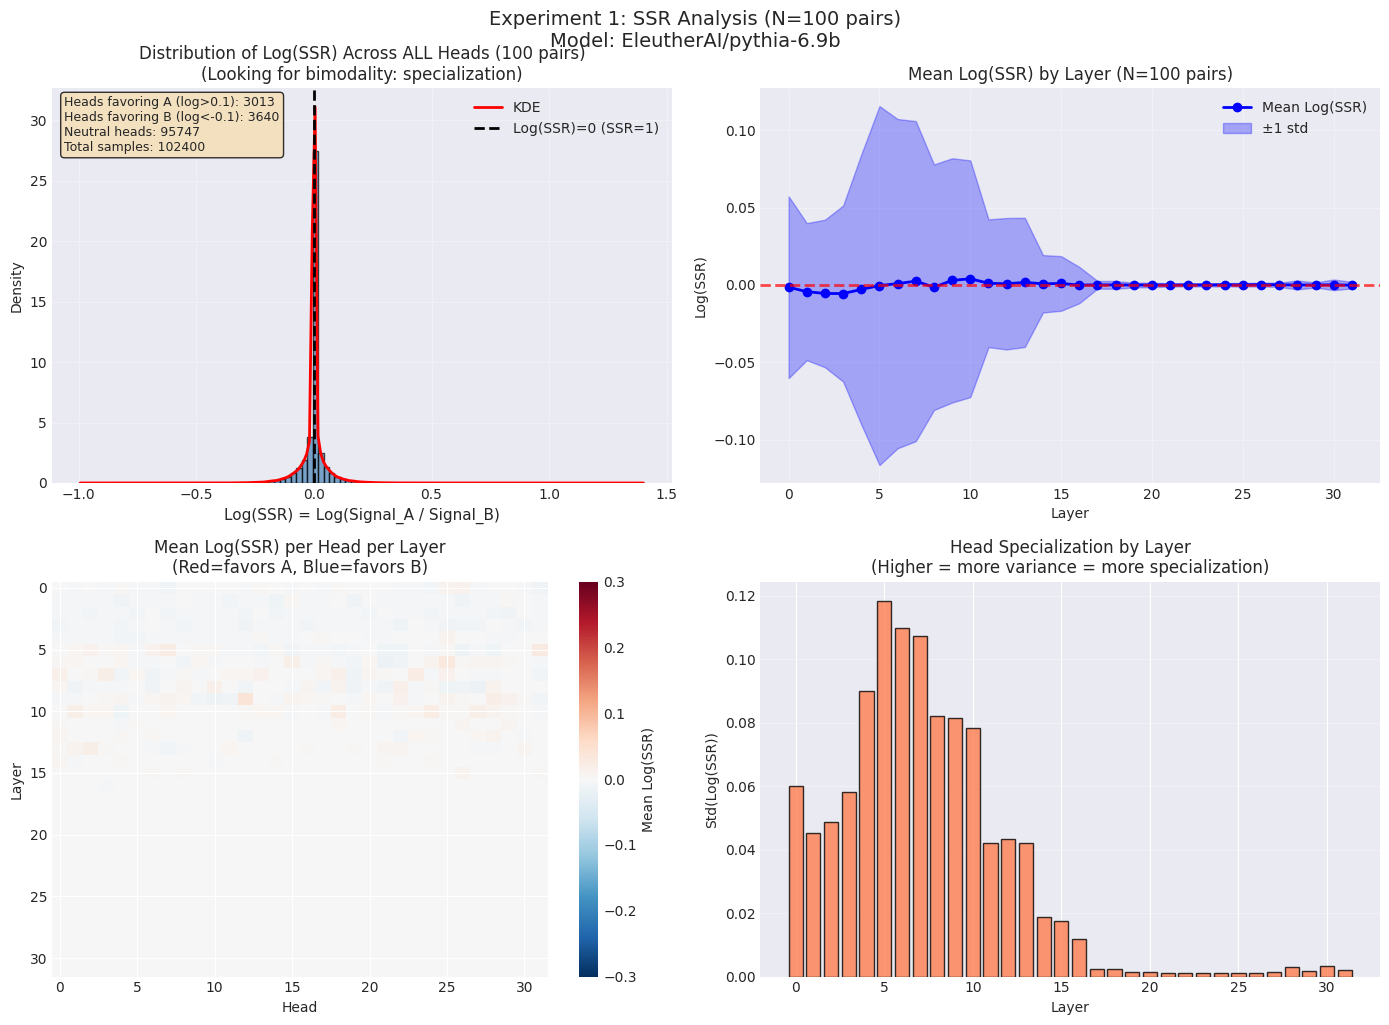


SSR Summary Statistics (Aggregated Across All Pairs)
Total heads analyzed: 102400
Number of text pairs: 100

Log(SSR) statistics:
  Mean: -0.0015 ± 0.0510
  Median: 0.0000
  Min:  -0.4941 (SSR = 0.6101)
  Max:  0.9012 (SSR = 2.4626)

Specialization analysis:
  Heads favoring A (SSR > 1.1): 3235 (3.2%)
  Heads favoring B (SSR < 0.9): 3318 (3.2%)
  Neutral heads (0.9 ≤ SSR ≤ 1.1): 95847


In [153]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Histogram of Log(SSR) across ALL heads from ALL pairs
ax = axes[0, 0]
ax.hist(all_log_ssr, bins=60, density=True, alpha=0.7, color='steelblue', edgecolor='black')

# Add KDE
from scipy import stats as scipy_stats
kde = scipy_stats.gaussian_kde(all_log_ssr)
x_range = np.linspace(all_log_ssr.min() - 0.5, all_log_ssr.max() + 0.5, 200)
ax.plot(x_range, kde(x_range), 'r-', linewidth=2, label='KDE')
ax.axvline(x=0, color='black', linestyle='--', linewidth=2, label='Log(SSR)=0 (SSR=1)')
ax.set_xlabel('Log(SSR) = Log(Signal_A / Signal_B)', fontsize=11)
ax.set_ylabel('Density')
ax.set_title(f'Distribution of Log(SSR) Across ALL Heads ({len(text_pairs)} pairs)\n(Looking for bimodality: specialization)', fontsize=12)
ax.legend()
ax.grid(True, alpha=0.3)

# Add interpretation text
n_favor_A = (all_log_ssr > 0.1).sum()
n_favor_B = (all_log_ssr < -0.1).sum()
n_neutral = len(all_log_ssr) - n_favor_A - n_favor_B
ax.text(0.02, 0.98, f'Heads favoring A (log>0.1): {n_favor_A}\n'
                     f'Heads favoring B (log<-0.1): {n_favor_B}\n'
                     f'Neutral heads: {n_neutral}\n'
                     f'Total samples: {len(all_log_ssr)}',
        transform=ax.transAxes, fontsize=9, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# Plot 2: Mean SSR per layer with confidence intervals
ax = axes[0, 1]
layers = range(num_layers)
ax.plot(layers, np.log(ssr_mean_per_layer), 'b-o', linewidth=2, label='Mean Log(SSR)')
ax.fill_between(layers, 
                np.log(ssr_mean_per_layer) - np.log(1 + np.array(ssr_std_per_layer) / np.array(ssr_mean_per_layer)),
                np.log(ssr_mean_per_layer) + np.log(1 + np.array(ssr_std_per_layer) / np.array(ssr_mean_per_layer)),
                alpha=0.3, color='blue', label='±1 std')
ax.axhline(y=0, color='red', linestyle='--', linewidth=2, alpha=0.7)
ax.set_xlabel('Layer')
ax.set_ylabel('Log(SSR)')
ax.set_title(f'Mean Log(SSR) by Layer (N={len(text_pairs)} pairs)')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 3: Heatmap of mean Log(SSR) per head per layer
ax = axes[1, 0]
# Compute mean SSR per head per layer across all pairs
ssr_matrix = np.zeros((num_layers, num_heads))
for layer_idx in range(num_layers):
    for head_idx in range(num_heads):
        head_ssrs = []
        for pair_result in all_results:
            head_ssrs.append(pair_result['ssr_by_layer'][layer_idx][head_idx])
        ssr_matrix[layer_idx, head_idx] = np.mean(head_ssrs)

im = ax.imshow(np.log(ssr_matrix), aspect='auto', cmap='RdBu_r', vmin=-0.3, vmax=0.3)
ax.set_xlabel('Head')
ax.set_ylabel('Layer')
ax.set_title('Mean Log(SSR) per Head per Layer\n(Red=favors A, Blue=favors B)')
plt.colorbar(im, ax=ax, label='Mean Log(SSR)')

# Plot 4: Specialization variance per layer
ax = axes[1, 1]
layer_variance = []
for layer_idx in range(num_layers):
    layer_ssrs = []
    for pair_result in all_results:
        layer_ssrs.extend(np.log(pair_result['ssr_by_layer'][layer_idx]))
    layer_variance.append(np.std(layer_ssrs))

ax.bar(range(num_layers), layer_variance, color='coral', edgecolor='black', alpha=0.8)
ax.set_xlabel('Layer')
ax.set_ylabel('Std(Log(SSR))')
ax.set_title('Head Specialization by Layer\n(Higher = more variance = more specialization)')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.suptitle(f'Experiment 1: SSR Analysis (N={len(text_pairs)} pairs)\nModel: {MODEL_NAME}', y=1.02, fontsize=14)
plt.savefig('exp1_ssr_analysis_aggregated.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary statistics
print("\n" + "="*60)
print("SSR Summary Statistics (Aggregated Across All Pairs)")
print("="*60)
print(f"Total heads analyzed: {len(all_log_ssr)}")
print(f"Number of text pairs: {len(text_pairs)}")
print(f"\nLog(SSR) statistics:")
print(f"  Mean: {all_log_ssr.mean():.4f} ± {all_log_ssr.std():.4f}")
print(f"  Median: {np.median(all_log_ssr):.4f}")
print(f"  Min:  {all_log_ssr.min():.4f} (SSR = {np.exp(all_log_ssr.min()):.4f})")
print(f"  Max:  {all_log_ssr.max():.4f} (SSR = {np.exp(all_log_ssr.max()):.4f})")
print(f"\nSpecialization analysis:")
print(f"  Heads favoring A (SSR > 1.1): {(all_ssr_values_combined > 1.1).sum()} ({100*(all_ssr_values_combined > 1.1).mean():.1f}%)")
print(f"  Heads favoring B (SSR < 0.9): {(all_ssr_values_combined < 0.9).sum()} ({100*(all_ssr_values_combined < 0.9).mean():.1f}%)")
print(f"  Neutral heads (0.9 ≤ SSR ≤ 1.1): {((all_ssr_values_combined >= 0.9) & (all_ssr_values_combined <= 1.1)).sum()}")

### Experiment 2: Value Leakage (Logit Impact) - Aggregated Results

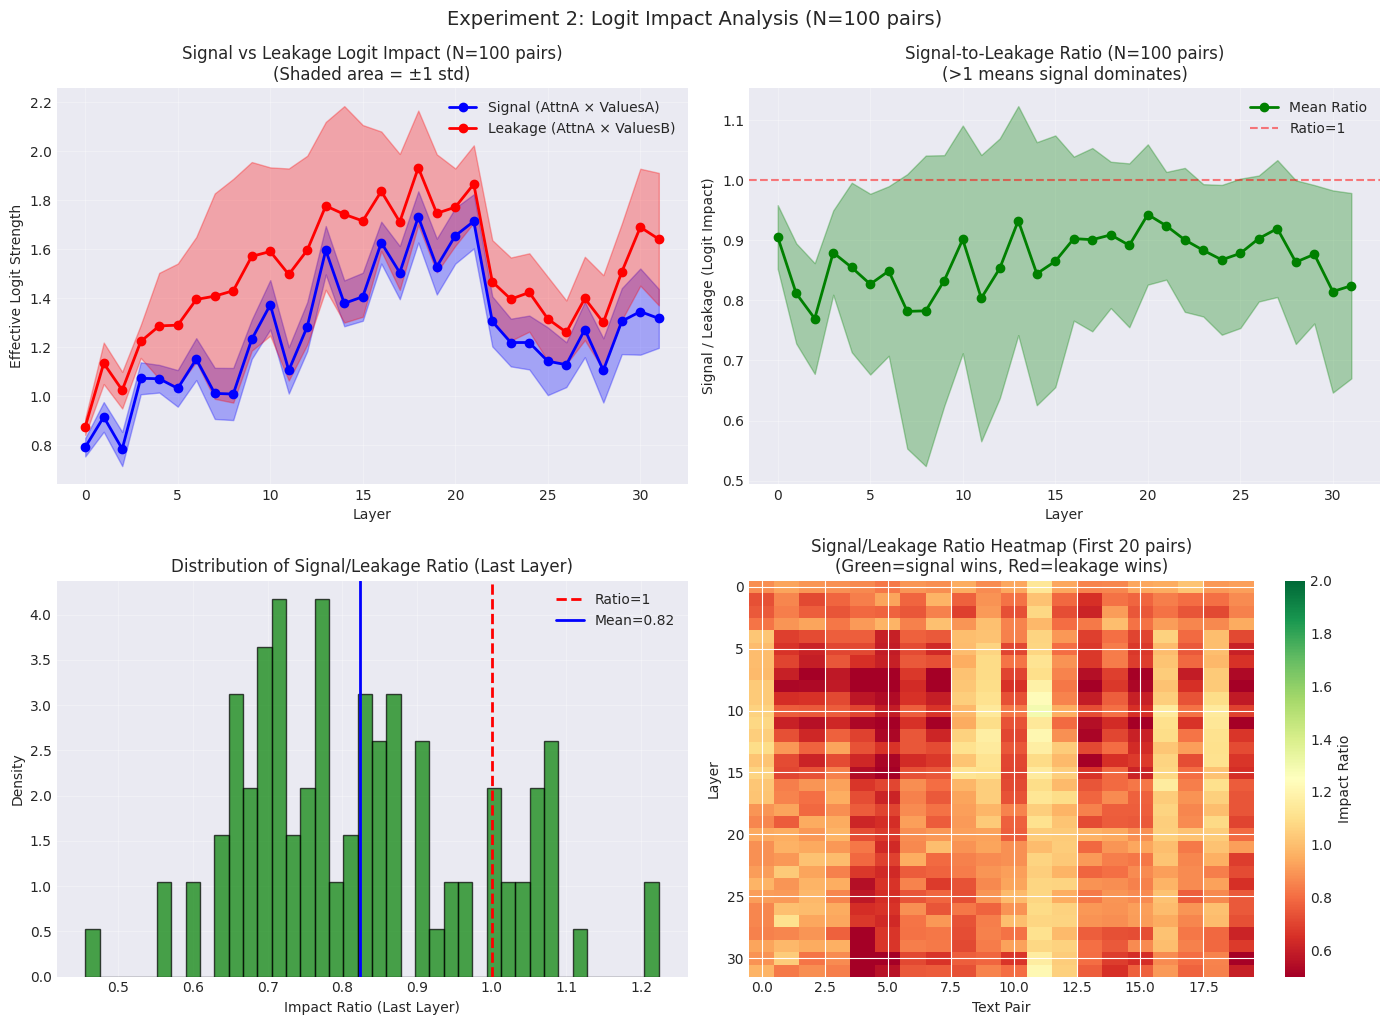


Logit Impact Summary (Aggregated)
Number of pairs: 100

Mean Signal/Leakage ratio across all layers: 0.866 ± 0.147
Mean ratio at last layer: 0.824 ± 0.154
Signal effective strength (last layer): 1.317 ± 0.120
Leakage effective strength (last layer): 1.641 ± 0.270

Interpretation:
  ✗ Leakage competitive with signal (ratio ≤ 1)


In [154]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Effective Logit Strength (mean ± std)
ax = axes[0, 0]
layers = range(num_layers)
ax.plot(layers, signal_mean, 'b-o', label='Signal (AttnA × ValuesA)', linewidth=2)
ax.fill_between(layers, signal_mean - signal_std, signal_mean + signal_std, alpha=0.3, color='blue')
ax.plot(layers, leakage_mean, 'r-o', label='Leakage (AttnA × ValuesB)', linewidth=2)
ax.fill_between(layers, leakage_mean - leakage_std, leakage_mean + leakage_std, alpha=0.3, color='red')
ax.set_xlabel('Layer')
ax.set_ylabel('Effective Logit Strength')
ax.set_title(f'Signal vs Leakage Logit Impact (N={len(text_pairs)} pairs)\n(Shaded area = ±1 std)')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Signal-to-Leakage Ratio
ax = axes[0, 1]
ax.plot(layers, impact_ratios_mean, 'g-o', linewidth=2, label='Mean Ratio')
ax.fill_between(layers, impact_ratios_mean - impact_ratios_std, 
                impact_ratios_mean + impact_ratios_std, alpha=0.3, color='green')
ax.axhline(y=1.0, color='r', linestyle='--', alpha=0.5, label='Ratio=1')
ax.set_xlabel('Layer')
ax.set_ylabel('Signal / Leakage (Logit Impact)')
ax.set_title(f'Signal-to-Leakage Ratio (N={len(text_pairs)} pairs)\n(>1 means signal dominates)')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 3: Distribution of ratios across all pairs (last layer)
ax = axes[1, 0]
last_layer_ratios = [r['impact_ratios'][-1] for r in all_results]
ax.hist(last_layer_ratios, bins=40, density=True, alpha=0.7, color='green', edgecolor='black')
ax.axvline(x=1.0, color='red', linestyle='--', linewidth=2, label='Ratio=1')
ax.axvline(x=np.mean(last_layer_ratios), color='blue', linestyle='-', linewidth=2, label=f'Mean={np.mean(last_layer_ratios):.2f}')
ax.set_xlabel('Impact Ratio (Last Layer)')
ax.set_ylabel('Density')
ax.set_title('Distribution of Signal/Leakage Ratio (Last Layer)')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 4: Per-pair variation (heatmap of ratios)
ax = axes[1, 1]
# Show subset of pairs for readability
n_show = min(20, len(all_results))
ratio_matrix = np.array([r['impact_ratios'] for r in all_results[:n_show]])
im = ax.imshow(ratio_matrix.T, aspect='auto', cmap='RdYlGn', vmin=0.5, vmax=2.0)
ax.set_xlabel('Text Pair')
ax.set_ylabel('Layer')
ax.set_title(f'Signal/Leakage Ratio Heatmap (First {n_show} pairs)\n(Green=signal wins, Red=leakage wins)')
plt.colorbar(im, ax=ax, label='Impact Ratio')

plt.tight_layout()
plt.suptitle(f'Experiment 2: Logit Impact Analysis (N={len(text_pairs)} pairs)', y=1.02, fontsize=14)
plt.savefig('exp2_value_leakage_aggregated.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary
print("\n" + "="*60)
print("Logit Impact Summary (Aggregated)")
print("="*60)
print(f"Number of pairs: {len(text_pairs)}")
print(f"\nMean Signal/Leakage ratio across all layers: {impact_ratios_mean.mean():.3f} ± {impact_ratios_std.mean():.3f}")
print(f"Mean ratio at last layer: {impact_ratios_mean[-1]:.3f} ± {impact_ratios_std[-1]:.3f}")
print(f"Signal effective strength (last layer): {signal_mean[-1]:.3f} ± {signal_std[-1]:.3f}")
print(f"Leakage effective strength (last layer): {leakage_mean[-1]:.3f} ± {leakage_std[-1]:.3f}")
print(f"\nInterpretation:")
if impact_ratios_mean.mean() > 1:
    print(f"  ✓ Signal dominates leakage on average (ratio > 1)")
else:
    print(f"  ✗ Leakage competitive with signal (ratio ≤ 1)")

### Experiment 3: Attention Overlap - Aggregated Results

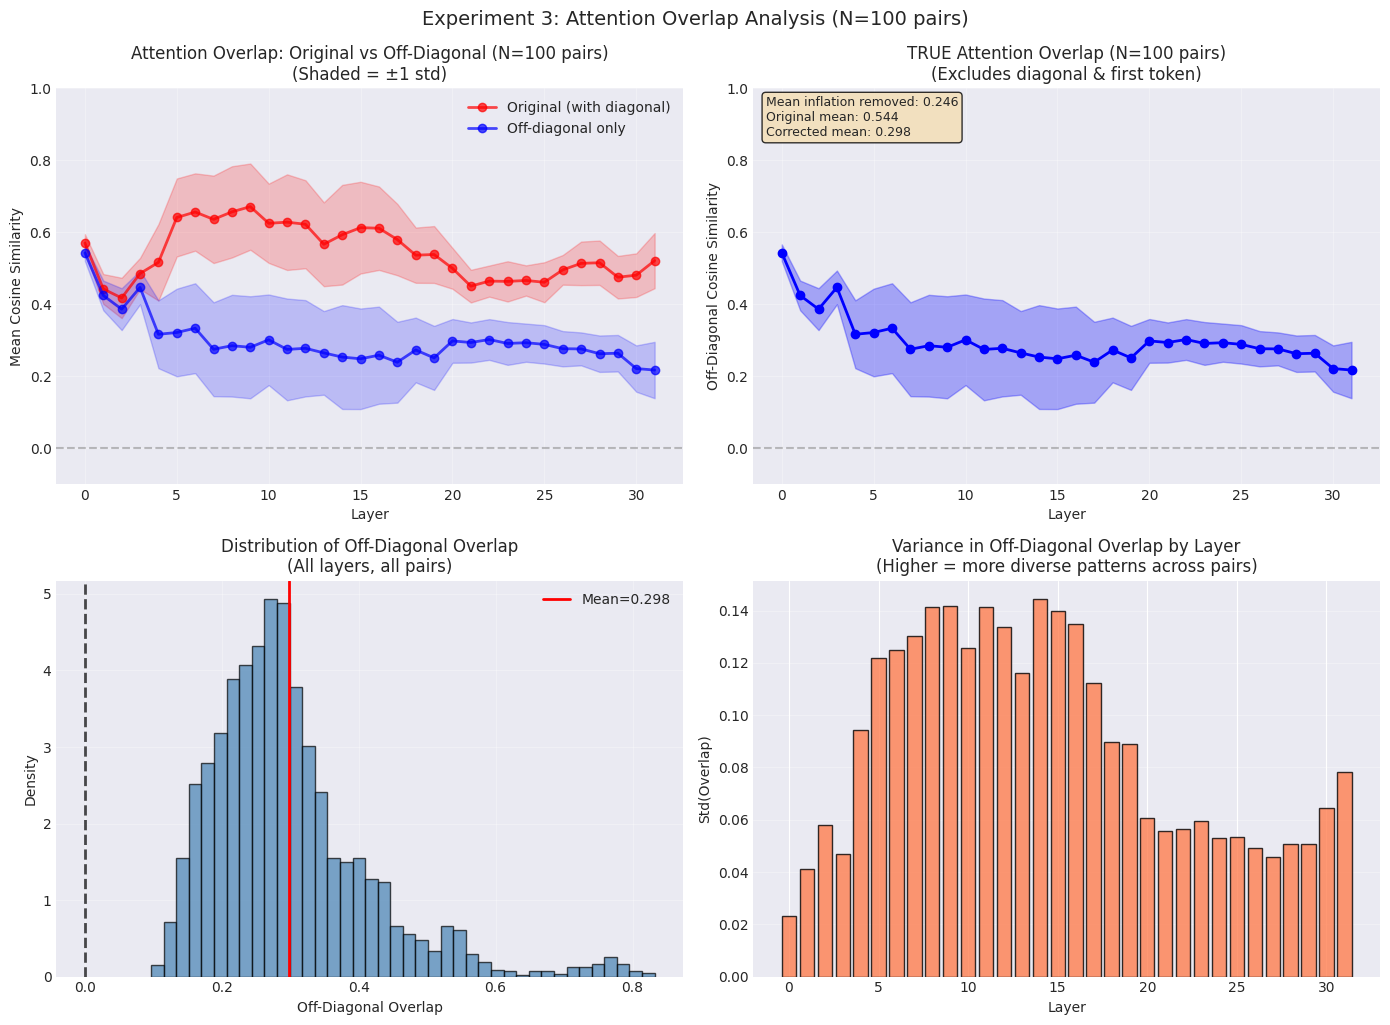


Attention Overlap Summary (Aggregated)
Number of pairs: 100

ORIGINAL (with diagonal + first token):
  Mean overlap: 0.5437 ± 0.0823

CORRECTED (off-diagonal only):
  Mean overlap: 0.2977 ± 0.0884
  Max at layer 0: 0.5426
  Min at layer 31: 0.2168

Inflation from diagonal: 0.2461


In [155]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Comparison of original vs corrected overlap
ax = axes[0, 0]
layers = range(num_layers)
ax.plot(layers, overlap_original_mean, 'r-o', linewidth=2, label='Original (with diagonal)', alpha=0.7)
ax.fill_between(layers, overlap_original_mean - overlap_original_std, 
                overlap_original_mean + overlap_original_std, alpha=0.2, color='red')
ax.plot(layers, overlap_corrected_mean, 'b-o', linewidth=2, label='Off-diagonal only', alpha=0.7)
ax.fill_between(layers, overlap_corrected_mean - overlap_corrected_std,
                overlap_corrected_mean + overlap_corrected_std, alpha=0.2, color='blue')
ax.set_xlabel('Layer')
ax.set_ylabel('Mean Cosine Similarity')
ax.set_title(f'Attention Overlap: Original vs Off-Diagonal (N={len(text_pairs)} pairs)\n(Shaded = ±1 std)')
ax.axhline(y=0.0, color='gray', linestyle='--', alpha=0.5)
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(-0.1, 1.0)

# Plot 2: Off-diagonal overlap only (the meaningful metric)
ax = axes[0, 1]
ax.plot(layers, overlap_corrected_mean, 'b-o', linewidth=2)
ax.fill_between(layers, overlap_corrected_mean - overlap_corrected_std,
                overlap_corrected_mean + overlap_corrected_std, alpha=0.3, color='blue')
ax.set_xlabel('Layer')
ax.set_ylabel('Off-Diagonal Cosine Similarity')
ax.set_title(f'TRUE Attention Overlap (N={len(text_pairs)} pairs)\n(Excludes diagonal & first token)')
ax.axhline(y=0.0, color='gray', linestyle='--', alpha=0.5)
ax.grid(True, alpha=0.3)
ax.set_ylim(-0.1, 1.0)

# Add annotation
mean_inflation = overlap_original_mean.mean() - overlap_corrected_mean.mean()
ax.text(0.02, 0.98, f'Mean inflation removed: {mean_inflation:.3f}\n'
                     f'Original mean: {overlap_original_mean.mean():.3f}\n'
                     f'Corrected mean: {overlap_corrected_mean.mean():.3f}',
        transform=ax.transAxes, fontsize=9, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# Plot 3: Distribution of corrected overlap (all layers combined)
ax = axes[1, 0]
all_corrected_overlaps = np.concatenate(overlap_corrected_all)
ax.hist(all_corrected_overlaps, bins=40, density=True, alpha=0.7, color='steelblue', edgecolor='black')
ax.axvline(x=0, color='black', linestyle='--', linewidth=2, alpha=0.7)
ax.axvline(x=np.mean(all_corrected_overlaps), color='red', linestyle='-', linewidth=2, 
           label=f'Mean={np.mean(all_corrected_overlaps):.3f}')
ax.set_xlabel('Off-Diagonal Overlap')
ax.set_ylabel('Density')
ax.set_title('Distribution of Off-Diagonal Overlap\n(All layers, all pairs)')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 4: Per-layer variance in overlap
ax = axes[1, 1]
ax.bar(layers, overlap_corrected_std, color='coral', edgecolor='black', alpha=0.8)
ax.set_xlabel('Layer')
ax.set_ylabel('Std(Overlap)')
ax.set_title('Variance in Off-Diagonal Overlap by Layer\n(Higher = more diverse patterns across pairs)')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.suptitle(f'Experiment 3: Attention Overlap Analysis (N={len(text_pairs)} pairs)', y=1.02, fontsize=14)
plt.savefig('exp3_attention_overlap_aggregated.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*60)
print("Attention Overlap Summary (Aggregated)")
print("="*60)
print(f"Number of pairs: {len(text_pairs)}")
print(f"\nORIGINAL (with diagonal + first token):")
print(f"  Mean overlap: {overlap_original_mean.mean():.4f} ± {overlap_original_std.mean():.4f}")
print(f"\nCORRECTED (off-diagonal only):")
print(f"  Mean overlap: {overlap_corrected_mean.mean():.4f} ± {overlap_corrected_std.mean():.4f}")
print(f"  Max at layer {np.argmax(overlap_corrected_mean)}: {np.max(overlap_corrected_mean):.4f}")
print(f"  Min at layer {np.argmin(overlap_corrected_mean)}: {np.min(overlap_corrected_mean):.4f}")
print(f"\nInflation from diagonal: {mean_inflation:.4f}")

### Experiment 4: Additivity Check (Linearity Verification) - Aggregated Results

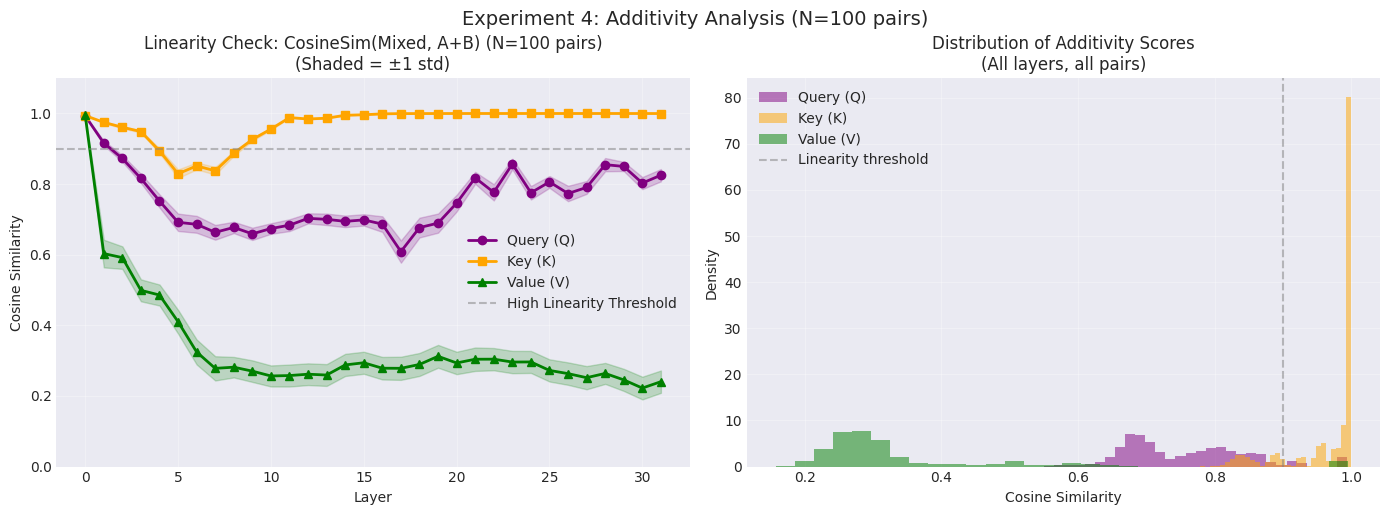


Additivity Summary (Aggregated)
Number of pairs: 100

Mean Additivity Scores (averaged across all layers and pairs):
  Query (Q):  0.7568 ± 0.0180
  Key (K):    0.9689 ± 0.0020
  Value (V):  0.3365 ± 0.0309

Fraction above 0.9 (high linearity):
  Query (Q):  6.3%
  Key (K):    85.1%
  Value (V):  3.1%


In [156]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Mean additivity scores with confidence intervals
ax = axes[0]
layers = range(num_layers)
ax.plot(layers, additivity_Q_mean, 'o-', label='Query (Q)', color='purple', linewidth=2)
ax.fill_between(layers, additivity_Q_mean - additivity_Q_std, 
                additivity_Q_mean + additivity_Q_std, alpha=0.2, color='purple')
ax.plot(layers, additivity_K_mean, 's-', label='Key (K)', color='orange', linewidth=2)
ax.fill_between(layers, additivity_K_mean - additivity_K_std,
                additivity_K_mean + additivity_K_std, alpha=0.2, color='orange')
ax.plot(layers, additivity_V_mean, '^-', label='Value (V)', color='green', linewidth=2)
ax.fill_between(layers, additivity_V_mean - additivity_V_std,
                additivity_V_mean + additivity_V_std, alpha=0.2, color='green')

ax.set_title(f'Linearity Check: CosineSim(Mixed, A+B) (N={len(text_pairs)} pairs)\n(Shaded = ±1 std)')
ax.set_xlabel('Layer')
ax.set_ylabel('Cosine Similarity')
ax.set_ylim(0, 1.1)
ax.axhline(y=0.9, color='gray', linestyle='--', alpha=0.5, label='High Linearity Threshold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Distribution of additivity scores (all layers, all pairs)
ax = axes[1]
all_Q = np.concatenate(additivity_Q_all)
all_K = np.concatenate(additivity_K_all)
all_V = np.concatenate(additivity_V_all)

ax.hist(all_Q, bins=30, alpha=0.5, label='Query (Q)', color='purple', density=True)
ax.hist(all_K, bins=30, alpha=0.5, label='Key (K)', color='orange', density=True)
ax.hist(all_V, bins=30, alpha=0.5, label='Value (V)', color='green', density=True)
ax.axvline(x=0.9, color='gray', linestyle='--', alpha=0.5, label='Linearity threshold')
ax.set_xlabel('Cosine Similarity')
ax.set_ylabel('Density')
ax.set_title('Distribution of Additivity Scores\n(All layers, all pairs)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.suptitle(f'Experiment 4: Additivity Analysis (N={len(text_pairs)} pairs)', y=1.02, fontsize=14)
plt.savefig('exp4_additivity_aggregated.png', dpi=150, bbox_inches='tight')
plt.show()

# Print stats
print("\n" + "="*60)
print("Additivity Summary (Aggregated)")
print("="*60)
print(f"Number of pairs: {len(text_pairs)}")
print(f"\nMean Additivity Scores (averaged across all layers and pairs):")
print(f"  Query (Q):  {additivity_Q_mean.mean():.4f} ± {additivity_Q_std.mean():.4f}")
print(f"  Key (K):    {additivity_K_mean.mean():.4f} ± {additivity_K_std.mean():.4f}")
print(f"  Value (V):  {additivity_V_mean.mean():.4f} ± {additivity_V_std.mean():.4f}")
print(f"\nFraction above 0.9 (high linearity):")
print(f"  Query (Q):  {(all_Q > 0.9).mean()*100:.1f}%")
print(f"  Key (K):    {(all_K > 0.9).mean()*100:.1f}%")
print(f"  Value (V):  {(all_V > 0.9).mean()*100:.1f}%")

### Experiment 4b: Baseline - Cross-Pair Additivity Comparison

**Experiment 4** measures: $\cos(K_{mixed}^{(i)}, K_A^{(i)} + K_B^{(i)})$ — additivity within the **same** pair.

**Baseline** measures: $\cos(K_{mixed}^{(i)}, K_A^{(j)} + K_B^{(j)})$ where $i \neq j$ — comparing K_mixed from one pair with the sum of Keys from a **different** pair.

If baseline is also high, then the additivity result is less meaningful (any K_mixed looks like any K_A+K_B).
If baseline is low but Exp4 is high, then additivity is pair-specific and meaningful.


In [157]:
# Compute baseline: cos(K_mixed_i, K_A_j + K_B_j) where i != j
# This tests if additivity is pair-specific or just a general property

import time

NUM_BASELINE_PAIRS = 15
num_cross_comparisons = NUM_BASELINE_PAIRS * (NUM_BASELINE_PAIRS - 1)  # i != j, order matters for debugging

print(f"Computing baseline from {NUM_BASELINE_PAIRS} pairs -> {num_cross_comparisons} cross-pair comparisons")
print(f"Model device: {next(model.parameters()).device}")
print(f"num_layers={num_layers}, num_heads={num_heads}")

# Collect K_mixed, K_A, K_B, Q_mixed for each pair
all_K_mixed = []  # [pair_idx][layer_idx] -> tensor
all_K_A = []
all_K_B = []
all_Q_mixed = []  # For attention score computation
all_Q_A = []  # For Experiment 4d (Query additivity)
all_Q_B = []  # For Experiment 4d (Query additivity)

start_time = time.time()

for pair_idx in tqdm(range(NUM_BASELINE_PAIRS), desc="Collecting K tensors"):
    text_a, text_b = text_pairs[pair_idx]
    
    # Tokenize
    input_ids_A, attention_mask_A, input_ids_B, attention_mask_B, common_length = \
        tokenize_pair_to_min_length(text_a, text_b)
    
    if common_length < 3:
        print(f"  Skipping pair {pair_idx}: too short ({common_length} tokens)")
        continue
    
    attention_mask_mixed = attention_mask_A
    
    with torch.no_grad():
        # Forward pass for text A alone
        result_A = extract_qkv_with_hooks(model, input_ids_A, attention_mask_A)
        # Forward pass for text B alone  
        result_B = extract_qkv_with_hooks(model, input_ids_B, attention_mask_B)
        # Forward pass for mixed embeddings
        mixed_embeds, _, _ = create_mixed_embeddings(model, input_ids_A, input_ids_B)
        result_mixed = forward_with_embeddings(model, mixed_embeds, attention_mask_mixed)
    
    # Store K and Q tensors for each layer (move to CPU to save GPU memory)
    K_mixed_per_layer = []
    K_A_per_layer = []
    K_B_per_layer = []
    Q_mixed_per_layer = []
    Q_A_per_layer = []
    Q_B_per_layer = []
    
    for layer_idx in range(num_layers):
        K_mixed_per_layer.append(result_mixed.keys[layer_idx].cpu())
        K_A_per_layer.append(result_A.internals.keys[layer_idx].cpu())
        K_B_per_layer.append(result_B.internals.keys[layer_idx].cpu())
        Q_mixed_per_layer.append(result_mixed.queries[layer_idx].cpu())
        Q_A_per_layer.append(result_A.internals.queries[layer_idx].cpu())
        Q_B_per_layer.append(result_B.internals.queries[layer_idx].cpu())
    
    all_K_mixed.append(K_mixed_per_layer)
    all_K_A.append(K_A_per_layer)
    all_K_B.append(K_B_per_layer)
    all_Q_mixed.append(Q_mixed_per_layer)
    all_Q_A.append(Q_A_per_layer)
    all_Q_B.append(Q_B_per_layer)
    
    if pair_idx == 0:
        print(f"  First pair: K_mixed shape = {K_mixed_per_layer[0].shape}")

elapsed = time.time() - start_time
print(f"\nCollected K tensors from {len(all_K_mixed)} pairs in {elapsed:.1f}s ({elapsed/len(all_K_mixed):.1f}s per pair)")


Computing baseline from 15 pairs -> 210 cross-pair comparisons
Model device: cuda:0
num_layers=32, num_heads=32


  First pair: K_mixed shape = torch.Size([1, 32, 64, 128])

Collected K tensors from 15 pairs in 3.7s (0.2s per pair)


In [158]:
# Compute cross-pair baseline: cos(K_mixed_i, K_A_j + K_B_j) where i != j
from itertools import permutations

baseline_cos_sim_per_layer = []  # [num_layers] x [num_comparisons]

n_pairs = len(all_K_mixed)
print(f"Computing baseline for {n_pairs} pairs...")

for layer_idx in range(num_layers):
    layer_sims = []
    
    # All cross-pair comparisons: K_mixed from pair i vs (K_A + K_B) from pair j, where i != j
    for i in range(n_pairs):
        for j in range(n_pairs):
            if i == j:
                continue  # Skip same-pair (that's what Exp4 measures)
            
            K_mixed_i = all_K_mixed[i][layer_idx].float()  # [batch, heads, seq, dim]
            K_A_j = all_K_A[j][layer_idx].float()
            K_B_j = all_K_B[j][layer_idx].float()
            
            # Theoretical sum from pair j
            K_sum_j = K_A_j + K_B_j
            
            # Match sequence lengths (take minimum)
            min_seq = min(K_mixed_i.shape[2], K_sum_j.shape[2])
            K_mixed_i_trunc = K_mixed_i[:, :, :min_seq, :]
            K_sum_j_trunc = K_sum_j[:, :, :min_seq, :]
            
            # Compute cosine similarity along last dim and average
            cos_sim = F.cosine_similarity(K_mixed_i_trunc, K_sum_j_trunc, dim=-1).mean().item()
            layer_sims.append(cos_sim)
    
    baseline_cos_sim_per_layer.append(layer_sims)

# Convert to numpy for easier manipulation
baseline_cos_sim_per_layer = np.array(baseline_cos_sim_per_layer)  # [num_layers, num_comparisons]

baseline_mean = baseline_cos_sim_per_layer.mean(axis=1)  # [num_layers]
baseline_std = baseline_cos_sim_per_layer.std(axis=1)

print(f"Baseline computed: {baseline_cos_sim_per_layer.shape[1]} cross-pair comparisons per layer")
print(f"Mean baseline cos_sim across all layers: {baseline_mean.mean():.4f} ± {baseline_std.mean():.4f}")



Computing baseline for 15 pairs...
Baseline computed: 210 cross-pair comparisons per layer
Mean baseline cos_sim across all layers: 0.9407 ± 0.0022


In [159]:
# Additional baseline: how similar are K_sums to each other?
# cos(K_A_i + K_B_i, K_A_j + K_B_j) where i != j
# This tells us if ALL K sums are just similar to each other regardless of content

from itertools import combinations

ksum_similarity_per_layer = []  # [num_layers] x [num_comparisons]

for layer_idx in range(num_layers):
    layer_sims = []
    
    for i, j in combinations(range(n_pairs), 2):
        K_sum_i = (all_K_A[i][layer_idx] + all_K_B[i][layer_idx]).float()
        K_sum_j = (all_K_A[j][layer_idx] + all_K_B[j][layer_idx]).float()
        
        min_seq = min(K_sum_i.shape[2], K_sum_j.shape[2])
        K_sum_i = K_sum_i[:, :, :min_seq, :]
        K_sum_j = K_sum_j[:, :, :min_seq, :]
        
        cos_sim = F.cosine_similarity(K_sum_i, K_sum_j, dim=-1).mean().item()
        layer_sims.append(cos_sim)
    
    ksum_similarity_per_layer.append(layer_sims)

ksum_similarity_per_layer = np.array(ksum_similarity_per_layer)
ksum_mean = ksum_similarity_per_layer.mean(axis=1)
ksum_std = ksum_similarity_per_layer.std(axis=1)

print("="*60)
print("Additional Baseline: Similarity between K_sums")
print("="*60)
print(f"cos(K_A_i + K_B_i, K_A_j + K_B_j) where i≠j")
print(f"Mean: {ksum_mean.mean():.4f} ± {ksum_std.mean():.4f}")
print()
print("INTERPRETATION:")
if ksum_mean.mean() > 0.9:
    print(f"  All K_sums are very similar to each other ({ksum_mean.mean():.2%})!")
    print("  This explains why cross-pair baseline is high.")
    print("  K vectors are dominated by position, not content.")
else:
    print(f"  K_sums have moderate diversity ({ksum_mean.mean():.2%})")

Additional Baseline: Similarity between K_sums
cos(K_A_i + K_B_i, K_A_j + K_B_j) where i≠j
Mean: 0.9494 ± 0.0021

INTERPRETATION:
  All K_sums are very similar to each other (94.94%)!
  This explains why cross-pair baseline is high.
  K vectors are dominated by position, not content.


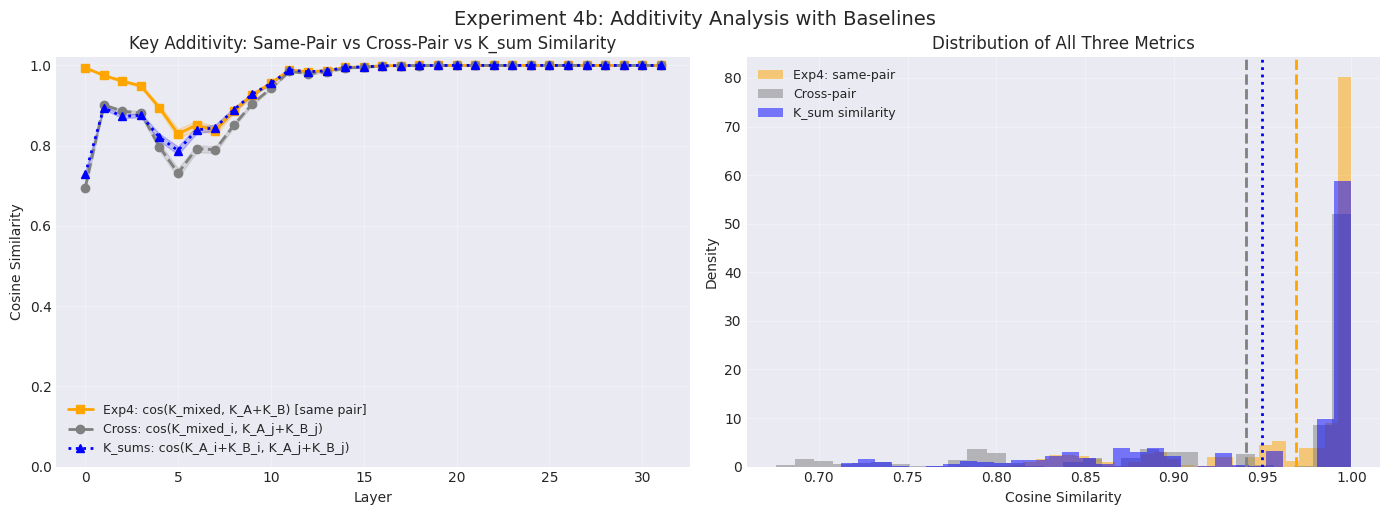


Exp 4b: Complete Additivity Analysis Summary

1. Exp 4 - SAME pair: cos(K_mixed_i, K_A_i + K_B_i)
   Mean: 0.9689 ± 0.0020

2. Baseline - CROSS pair: cos(K_mixed_i, K_A_j + K_B_j) where i≠j
   Mean: 0.9407 ± 0.0022

3. K_sum similarity: cos(K_A_i + K_B_i, K_A_j + K_B_j) where i≠j
   Mean: 0.9494 ± 0.0021

----------------------------------------------------------------------
KEY INSIGHTS:
----------------------------------------------------------------------

[!] ALL K_sums are very similar to each other (94.9%)
    This means K vectors are dominated by POSITION, not content!
    The high additivity score is largely due to positional similarity.

[*] Same-pair vs Cross-pair difference: 0.0283 (3.0% relative)
    => Small pair-specificity (mostly positional)


In [160]:
# Plot comparison: Exp 4 (same-pair) vs Baselines
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

layers = range(num_layers)

# Plot 1: All three metrics
ax = axes[0]
ax.plot(layers, additivity_K_mean, 's-', label='Exp4: cos(K_mixed, K_A+K_B) [same pair]', color='orange', linewidth=2)
ax.fill_between(layers, additivity_K_mean - additivity_K_std,
                additivity_K_mean + additivity_K_std, alpha=0.2, color='orange')

ax.plot(layers, baseline_mean, 'o--', label='Cross: cos(K_mixed_i, K_A_j+K_B_j)', color='gray', linewidth=2)
ax.fill_between(layers, baseline_mean - baseline_std,
                baseline_mean + baseline_std, alpha=0.2, color='gray')

ax.plot(layers, ksum_mean, '^:', label='K_sums: cos(K_A_i+K_B_i, K_A_j+K_B_j)', color='blue', linewidth=2)
ax.fill_between(layers, ksum_mean - ksum_std,
                ksum_mean + ksum_std, alpha=0.2, color='blue')

ax.set_title('Key Additivity: Same-Pair vs Cross-Pair vs K_sum Similarity')
ax.set_xlabel('Layer')
ax.set_ylabel('Cosine Similarity')
ax.set_ylim(0.0, 1.02)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# Plot 2: Distribution comparison
ax = axes[1]
ax.hist(all_K, bins=30, alpha=0.5, label='Exp4: same-pair', color='orange', density=True)
ax.hist(baseline_cos_sim_per_layer.flatten(), bins=30, alpha=0.5, label='Cross-pair', color='gray', density=True)
ax.hist(ksum_similarity_per_layer.flatten(), bins=30, alpha=0.5, label='K_sum similarity', color='blue', density=True)
ax.axvline(x=ksum_mean.mean(), color='blue', linestyle=':', linewidth=2)
ax.axvline(x=baseline_mean.mean(), color='gray', linestyle='--', linewidth=2)
ax.axvline(x=additivity_K_mean.mean(), color='orange', linestyle='--', linewidth=2)
ax.set_xlabel('Cosine Similarity')
ax.set_ylabel('Density')
ax.set_title('Distribution of All Three Metrics')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.suptitle('Experiment 4b: Additivity Analysis with Baselines', y=1.02, fontsize=14)
plt.savefig('exp4b_additivity_vs_baseline.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary statistics
print("\n" + "="*70)
print("Exp 4b: Complete Additivity Analysis Summary")
print("="*70)
print(f"\n1. Exp 4 - SAME pair: cos(K_mixed_i, K_A_i + K_B_i)")
print(f"   Mean: {additivity_K_mean.mean():.4f} ± {additivity_K_std.mean():.4f}")
print(f"\n2. Baseline - CROSS pair: cos(K_mixed_i, K_A_j + K_B_j) where i≠j")
print(f"   Mean: {baseline_mean.mean():.4f} ± {baseline_std.mean():.4f}")
print(f"\n3. K_sum similarity: cos(K_A_i + K_B_i, K_A_j + K_B_j) where i≠j")
print(f"   Mean: {ksum_mean.mean():.4f} ± {ksum_std.mean():.4f}")

print("\n" + "-"*70)
print("KEY INSIGHTS:")
print("-"*70)

# Check if K_sums are all similar
if ksum_mean.mean() > 0.9:
    print(f"\n[!] ALL K_sums are very similar to each other ({ksum_mean.mean():.1%})")
    print("    This means K vectors are dominated by POSITION, not content!")
    print("    The high additivity score is largely due to positional similarity.")

# Check pair-specificity
diff = additivity_K_mean.mean() - baseline_mean.mean()
print(f"\n[*] Same-pair vs Cross-pair difference: {diff:.4f} ({diff/baseline_mean.mean()*100:.1f}% relative)")

if diff > 0.05:
    print("    => Moderate pair-specificity exists")
elif diff > 0.02:
    print("    => Small pair-specificity (mostly positional)")
else:
    print("    => Negligible pair-specificity - K_mixed ≈ any K_sum")

### Experiment 4c: Attention Score Divergence

Cosine similarity may not capture meaningful differences. Let's compare how K_mixed vs (K_A + K_B) affect **actual attention patterns**:

$$\text{Attn}_{mixed} = \text{softmax}\left(\frac{Q_{mixed} \cdot K_{mixed}^T}{\sqrt{d}}\right)$$
$$\text{Attn}_{sum} = \text{softmax}\left(\frac{Q_{mixed} \cdot (K_A + K_B)^T}{\sqrt{d}}\right)$$

We measure KL-divergence and JS-divergence between these distributions.

In [161]:
# Compute attention score divergence: how different are attention patterns?
# Attn_mixed = softmax(Q_mixed @ K_mixed^T / sqrt(d))
# Attn_sum = softmax(Q_mixed @ (K_A + K_B)^T / sqrt(d))

def compute_attention_divergence(Q, K1, K2, scale):
    """
    Compute divergence between attention distributions using K1 vs K2.
    Returns KL divergence and JS divergence.
    """
    # Q: [batch, heads, seq, dim], K: [batch, heads, seq, dim]
    # Attention scores: [batch, heads, seq, seq]
    
    scores1 = torch.matmul(Q, K1.transpose(-2, -1)) * scale
    scores2 = torch.matmul(Q, K2.transpose(-2, -1)) * scale
    
    # Apply causal mask
    seq_len = scores1.shape[-1]
    causal_mask = torch.triu(torch.ones(seq_len, seq_len), diagonal=1).bool()
    scores1 = scores1.masked_fill(causal_mask.to(scores1.device), float('-inf'))
    scores2 = scores2.masked_fill(causal_mask.to(scores2.device), float('-inf'))
    
    # Softmax to get attention probs
    attn1 = F.softmax(scores1, dim=-1)
    attn2 = F.softmax(scores2, dim=-1)
    
    # Add small epsilon for numerical stability
    eps = 1e-10
    attn1 = attn1 + eps
    attn2 = attn2 + eps
    
    # Renormalize
    attn1 = attn1 / attn1.sum(dim=-1, keepdim=True)
    attn2 = attn2 / attn2.sum(dim=-1, keepdim=True)
    
    # KL divergence: KL(attn1 || attn2) - averaged over positions and heads
    kl_div = (attn1 * (attn1.log() - attn2.log())).sum(dim=-1).mean()
    
    # JS divergence (symmetric)
    m = 0.5 * (attn1 + attn2)
    js_div = 0.5 * (attn1 * (attn1.log() - m.log())).sum(dim=-1).mean() + \
             0.5 * (attn2 * (attn2.log() - m.log())).sum(dim=-1).mean()
    
    # Total Variation distance
    tv_dist = 0.5 * (attn1 - attn2).abs().sum(dim=-1).mean()
    
    return {
        'kl_div': kl_div.item(),
        'js_div': js_div.item(),
        'tv_dist': tv_dist.item()
    }

# Compute for each pair and layer
scale = 1.0 / np.sqrt(head_dim)

attn_divergence_same = []  # [pair][layer] - K_mixed vs (K_A + K_B) same pair
attn_divergence_cross = []  # [comparison][layer] - K_mixed_i vs (K_A_j + K_B_j) cross pair

print("Computing attention divergence...")
print(f"Scale factor: {scale:.4f} (head_dim={head_dim})")

# Same-pair divergence
for pair_idx in tqdm(range(len(all_Q_mixed)), desc="Same-pair attention"):
    pair_divs = []
    for layer_idx in range(num_layers):
        Q = all_Q_mixed[pair_idx][layer_idx].float()
        K_mixed = all_K_mixed[pair_idx][layer_idx].float()
        K_sum = (all_K_A[pair_idx][layer_idx] + all_K_B[pair_idx][layer_idx]).float()
        
        divs = compute_attention_divergence(Q, K_mixed, K_sum, scale)
        pair_divs.append(divs)
    attn_divergence_same.append(pair_divs)

print(f"Computed same-pair divergence for {len(attn_divergence_same)} pairs")

Computing attention divergence...
Scale factor: 0.0884 (head_dim=128)


Same-pair attention:   0%|          | 0/15 [00:00<?, ?it/s]

Computed same-pair divergence for 15 pairs


In [162]:
# Cross-pair divergence: K_mixed_i vs (K_A_j + K_B_j) where i != j
for i in tqdm(range(len(all_Q_mixed)), desc="Cross-pair attention"):
    for j in range(len(all_K_A)):
        if i == j:
            continue
        
        pair_divs = []
        for layer_idx in range(num_layers):
            Q = all_Q_mixed[i][layer_idx].float()
            K_mixed = all_K_mixed[i][layer_idx].float()
            K_sum_other = (all_K_A[j][layer_idx] + all_K_B[j][layer_idx]).float()
            
            # Match sequence lengths
            min_seq = min(Q.shape[2], K_sum_other.shape[2])
            Q_trunc = Q[:, :, :min_seq, :]
            K_mixed_trunc = K_mixed[:, :, :min_seq, :]
            K_sum_trunc = K_sum_other[:, :, :min_seq, :]
            
            divs = compute_attention_divergence(Q_trunc, K_mixed_trunc, K_sum_trunc, scale)
            pair_divs.append(divs)
        attn_divergence_cross.append(pair_divs)

print(f"Computed cross-pair divergence for {len(attn_divergence_cross)} comparisons")

Cross-pair attention:   0%|          | 0/15 [00:00<?, ?it/s]

Computed cross-pair divergence for 210 comparisons


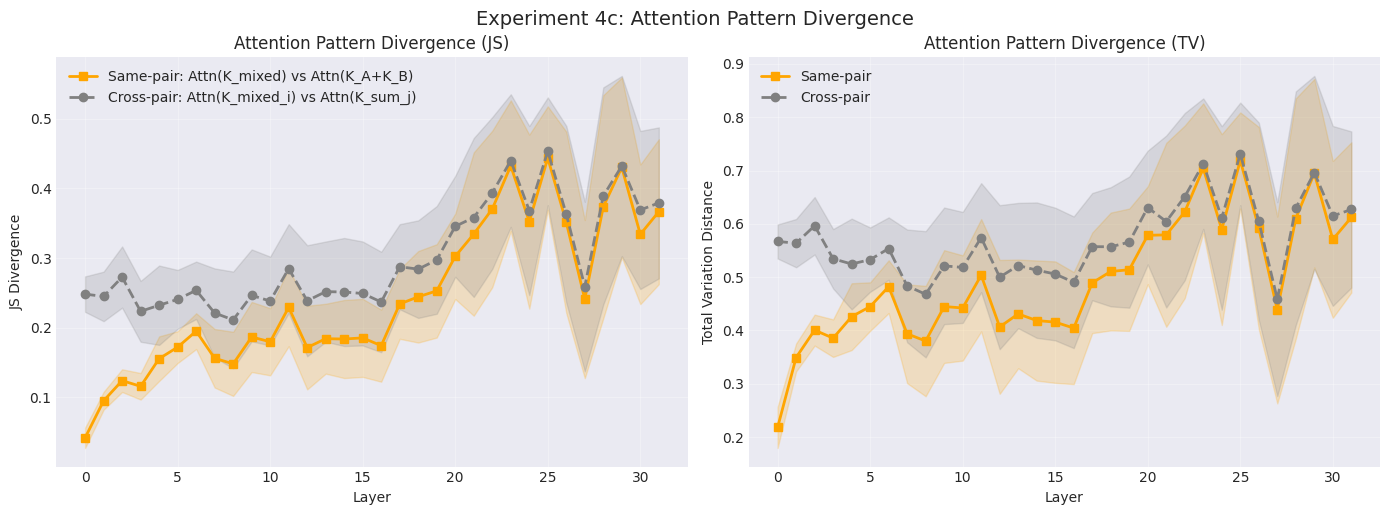


Exp 4c: Attention Pattern Divergence Summary

Same-pair: Attn(Q_mixed @ K_mixed) vs Attn(Q_mixed @ (K_A+K_B))
  JS Divergence: 0.242601 ± 0.067575
  TV Distance:   0.4929 ± 0.1107

Cross-pair: Attn(Q_mixed_i @ K_mixed_i) vs Attn(Q_mixed_i @ (K_A_j+K_B_j))
  JS Divergence: 0.298891 ± 0.079484
  TV Distance:   0.5694 ± 0.1185

----------------------------------------------------------------------
INTERPRETATION:
  Cross/Same JS ratio: 1.23x
  Cross/Same TV ratio: 1.16x

  [~] Cross-pair divergence is somewhat higher (1.2x)
      Some content-specificity exists, but effect is moderate.


In [163]:
# Aggregate and visualize attention divergence
# Extract JS divergence per layer (more interpretable than KL)

same_js_per_layer = np.array([[d['js_div'] for d in pair] for pair in attn_divergence_same])  # [pairs, layers]
same_tv_per_layer = np.array([[d['tv_dist'] for d in pair] for pair in attn_divergence_same])

cross_js_per_layer = np.array([[d['js_div'] for d in pair] for pair in attn_divergence_cross])  # [comparisons, layers]
cross_tv_per_layer = np.array([[d['tv_dist'] for d in pair] for pair in attn_divergence_cross])

# Mean and std across pairs/comparisons
same_js_mean = same_js_per_layer.mean(axis=0)
same_js_std = same_js_per_layer.std(axis=0)
same_tv_mean = same_tv_per_layer.mean(axis=0)
same_tv_std = same_tv_per_layer.std(axis=0)

cross_js_mean = cross_js_per_layer.mean(axis=0)
cross_js_std = cross_js_per_layer.std(axis=0)
cross_tv_mean = cross_tv_per_layer.mean(axis=0)
cross_tv_std = cross_tv_per_layer.std(axis=0)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
layers = range(num_layers)

# Plot 1: JS Divergence
ax = axes[0]
ax.plot(layers, same_js_mean, 's-', label='Same-pair: Attn(K_mixed) vs Attn(K_A+K_B)', color='orange', linewidth=2)
ax.fill_between(layers, same_js_mean - same_js_std, same_js_mean + same_js_std, alpha=0.2, color='orange')
ax.plot(layers, cross_js_mean, 'o--', label='Cross-pair: Attn(K_mixed_i) vs Attn(K_sum_j)', color='gray', linewidth=2)
ax.fill_between(layers, cross_js_mean - cross_js_std, cross_js_mean + cross_js_std, alpha=0.2, color='gray')
ax.set_xlabel('Layer')
ax.set_ylabel('JS Divergence')
ax.set_title('Attention Pattern Divergence (JS)')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Total Variation Distance
ax = axes[1]
ax.plot(layers, same_tv_mean, 's-', label='Same-pair', color='orange', linewidth=2)
ax.fill_between(layers, same_tv_mean - same_tv_std, same_tv_mean + same_tv_std, alpha=0.2, color='orange')
ax.plot(layers, cross_tv_mean, 'o--', label='Cross-pair', color='gray', linewidth=2)
ax.fill_between(layers, cross_tv_mean - cross_tv_std, cross_tv_mean + cross_tv_std, alpha=0.2, color='gray')
ax.set_xlabel('Layer')
ax.set_ylabel('Total Variation Distance')
ax.set_title('Attention Pattern Divergence (TV)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.suptitle('Experiment 4c: Attention Pattern Divergence', y=1.02, fontsize=14)
plt.savefig('exp4c_attention_divergence.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary
print("\n" + "="*70)
print("Exp 4c: Attention Pattern Divergence Summary")
print("="*70)
print(f"\nSame-pair: Attn(Q_mixed @ K_mixed) vs Attn(Q_mixed @ (K_A+K_B))")
print(f"  JS Divergence: {same_js_mean.mean():.6f} ± {same_js_std.mean():.6f}")
print(f"  TV Distance:   {same_tv_mean.mean():.4f} ± {same_tv_std.mean():.4f}")

print(f"\nCross-pair: Attn(Q_mixed_i @ K_mixed_i) vs Attn(Q_mixed_i @ (K_A_j+K_B_j))")
print(f"  JS Divergence: {cross_js_mean.mean():.6f} ± {cross_js_std.mean():.6f}")
print(f"  TV Distance:   {cross_tv_mean.mean():.4f} ± {cross_tv_std.mean():.4f}")

print("\n" + "-"*70)
print("INTERPRETATION:")
ratio_js = cross_js_mean.mean() / (same_js_mean.mean() + 1e-10)
ratio_tv = cross_tv_mean.mean() / (same_tv_mean.mean() + 1e-10)
print(f"  Cross/Same JS ratio: {ratio_js:.2f}x")
print(f"  Cross/Same TV ratio: {ratio_tv:.2f}x")

if ratio_js > 2:
    print(f"\n  [✓] Cross-pair divergence is {ratio_js:.1f}x higher than same-pair!")
    print("      K_mixed genuinely approximates (K_A + K_B) for the SAME pair.")
    print("      The additivity is content-specific, not just positional.")
elif ratio_js > 1.2:
    print(f"\n  [~] Cross-pair divergence is somewhat higher ({ratio_js:.1f}x)")
    print("      Some content-specificity exists, but effect is moderate.")
else:
    print(f"\n  [!] Cross-pair divergence is similar to same-pair ({ratio_js:.1f}x)")
    print("      Attention patterns are similar regardless of which K_sum is used.")
    print("      High 'additivity' may be a positional artifact.")

### Experiment 4d: Attention Score Divergence (Queries)

Similar to 4c, but now we compare how Q_mixed vs (Q_A + Q_B) affect **actual attention patterns**:

$$\text{Attn}_{mixed} = \text{softmax}\left(\frac{Q_{mixed} \cdot K_{mixed}^T}{\sqrt{d}}\right)$$
$$\text{Attn}_{sum} = \text{softmax}\left(\frac{(Q_A + Q_B) \cdot K_{mixed}^T}{\sqrt{d}}\right)$$

We measure KL-divergence and JS-divergence between these distributions.

In [164]:
# Compute attention score divergence: how different are attention patterns?
# Attn_mixed = softmax(Q_mixed @ K_mixed^T / sqrt(d))
# Attn_sum = softmax((Q_A + Q_B) @ K_mixed^T / sqrt(d))

# We already have the compute_attention_divergence function from Exp 4c

# Compute for each pair and layer
scale = 1.0 / np.sqrt(head_dim)

attn_divergence_Q_same = []  # [pair][layer] - Q_mixed vs (Q_A + Q_B) same pair
attn_divergence_Q_cross = []  # [comparison][layer] - Q_mixed_i vs (Q_A_j + Q_B_j) cross pair

print("Computing attention divergence for Queries...")
print(f"Scale factor: {scale:.4f} (head_dim={head_dim})")

# Same-pair divergence
for pair_idx in tqdm(range(len(all_Q_mixed)), desc="Same-pair attention (Q)"):
    pair_divs = []
    for layer_idx in range(num_layers):
        Q_mixed = all_Q_mixed[pair_idx][layer_idx].float()
        Q_sum = (all_Q_A[pair_idx][layer_idx] + all_Q_B[pair_idx][layer_idx]).float()
        K = all_K_mixed[pair_idx][layer_idx].float()
        
        # Compare Q_mixed vs Q_sum using the same K
        divs = compute_attention_divergence(Q_mixed, K, K, scale)
        divs_sum = compute_attention_divergence(Q_sum, K, K, scale)
        
        # We need to compare the two attention distributions
        # Recompute with proper comparison
        scores_mixed = torch.matmul(Q_mixed, K.transpose(-2, -1)) * scale
        scores_sum = torch.matmul(Q_sum, K.transpose(-2, -1)) * scale
        
        # Apply causal mask
        seq_len = scores_mixed.shape[-1]
        causal_mask = torch.triu(torch.ones(seq_len, seq_len), diagonal=1).bool()
        scores_mixed = scores_mixed.masked_fill(causal_mask.to(scores_mixed.device), float('-inf'))
        scores_sum = scores_sum.masked_fill(causal_mask.to(scores_sum.device), float('-inf'))
        
        # Softmax to get attention probs
        attn_mixed = F.softmax(scores_mixed, dim=-1)
        attn_sum = F.softmax(scores_sum, dim=-1)
        
        # Add small epsilon for numerical stability
        eps = 1e-10
        attn_mixed = attn_mixed + eps
        attn_sum = attn_sum + eps
        
        # Renormalize
        attn_mixed = attn_mixed / attn_mixed.sum(dim=-1, keepdim=True)
        attn_sum = attn_sum / attn_sum.sum(dim=-1, keepdim=True)
        
        # KL divergence: KL(attn_mixed || attn_sum)
        kl_div = (attn_mixed * (attn_mixed.log() - attn_sum.log())).sum(dim=-1).mean()
        
        # JS divergence (symmetric)
        m = 0.5 * (attn_mixed + attn_sum)
        js_div = 0.5 * (attn_mixed * (attn_mixed.log() - m.log())).sum(dim=-1).mean() + \
                 0.5 * (attn_sum * (attn_sum.log() - m.log())).sum(dim=-1).mean()
        
        # Total Variation distance
        tv_dist = 0.5 * (attn_mixed - attn_sum).abs().sum(dim=-1).mean()
        
        pair_divs.append({
            'kl_div': kl_div.item(),
            'js_div': js_div.item(),
            'tv_dist': tv_dist.item()
        })
    attn_divergence_Q_same.append(pair_divs)

print(f"Computed same-pair divergence for {len(attn_divergence_Q_same)} pairs")

Computing attention divergence for Queries...
Scale factor: 0.0884 (head_dim=128)


Same-pair attention (Q):   0%|          | 0/15 [00:00<?, ?it/s]

Computed same-pair divergence for 15 pairs


In [165]:
# Cross-pair divergence: Q_mixed_i vs (Q_A_j + Q_B_j) where i != j
for i in tqdm(range(len(all_Q_mixed)), desc="Cross-pair attention (Q)"):
    for j in range(len(all_Q_A)):
        if i == j:
            continue
        
        pair_divs = []
        for layer_idx in range(num_layers):
            Q_mixed = all_Q_mixed[i][layer_idx].float()
            Q_sum_other = (all_Q_A[j][layer_idx] + all_Q_B[j][layer_idx]).float()
            K = all_K_mixed[i][layer_idx].float()
            
            # Match sequence lengths
            min_seq = min(Q_mixed.shape[2], Q_sum_other.shape[2], K.shape[2])
            Q_mixed_trunc = Q_mixed[:, :, :min_seq, :]
            Q_sum_trunc = Q_sum_other[:, :, :min_seq, :]
            K_trunc = K[:, :, :min_seq, :]
            
            # Compute attention scores
            scores_mixed = torch.matmul(Q_mixed_trunc, K_trunc.transpose(-2, -1)) * scale
            scores_sum = torch.matmul(Q_sum_trunc, K_trunc.transpose(-2, -1)) * scale
            
            # Apply causal mask
            seq_len = scores_mixed.shape[-1]
            causal_mask = torch.triu(torch.ones(seq_len, seq_len), diagonal=1).bool()
            scores_mixed = scores_mixed.masked_fill(causal_mask.to(scores_mixed.device), float('-inf'))
            scores_sum = scores_sum.masked_fill(causal_mask.to(scores_sum.device), float('-inf'))
            
            # Softmax to get attention probs
            attn_mixed = F.softmax(scores_mixed, dim=-1)
            attn_sum = F.softmax(scores_sum, dim=-1)
            
            # Add small epsilon for numerical stability
            eps = 1e-10
            attn_mixed = attn_mixed + eps
            attn_sum = attn_sum + eps
            
            # Renormalize
            attn_mixed = attn_mixed / attn_mixed.sum(dim=-1, keepdim=True)
            attn_sum = attn_sum / attn_sum.sum(dim=-1, keepdim=True)
            
            # KL divergence
            kl_div = (attn_mixed * (attn_mixed.log() - attn_sum.log())).sum(dim=-1).mean()
            
            # JS divergence
            m = 0.5 * (attn_mixed + attn_sum)
            js_div = 0.5 * (attn_mixed * (attn_mixed.log() - m.log())).sum(dim=-1).mean() + \
                     0.5 * (attn_sum * (attn_sum.log() - m.log())).sum(dim=-1).mean()
            
            # Total Variation distance
            tv_dist = 0.5 * (attn_mixed - attn_sum).abs().sum(dim=-1).mean()
            
            pair_divs.append({
                'kl_div': kl_div.item(),
                'js_div': js_div.item(),
                'tv_dist': tv_dist.item()
            })
        attn_divergence_Q_cross.append(pair_divs)

print(f"Computed cross-pair divergence for {len(attn_divergence_Q_cross)} comparisons")

Cross-pair attention (Q):   0%|          | 0/15 [00:00<?, ?it/s]

Computed cross-pair divergence for 210 comparisons


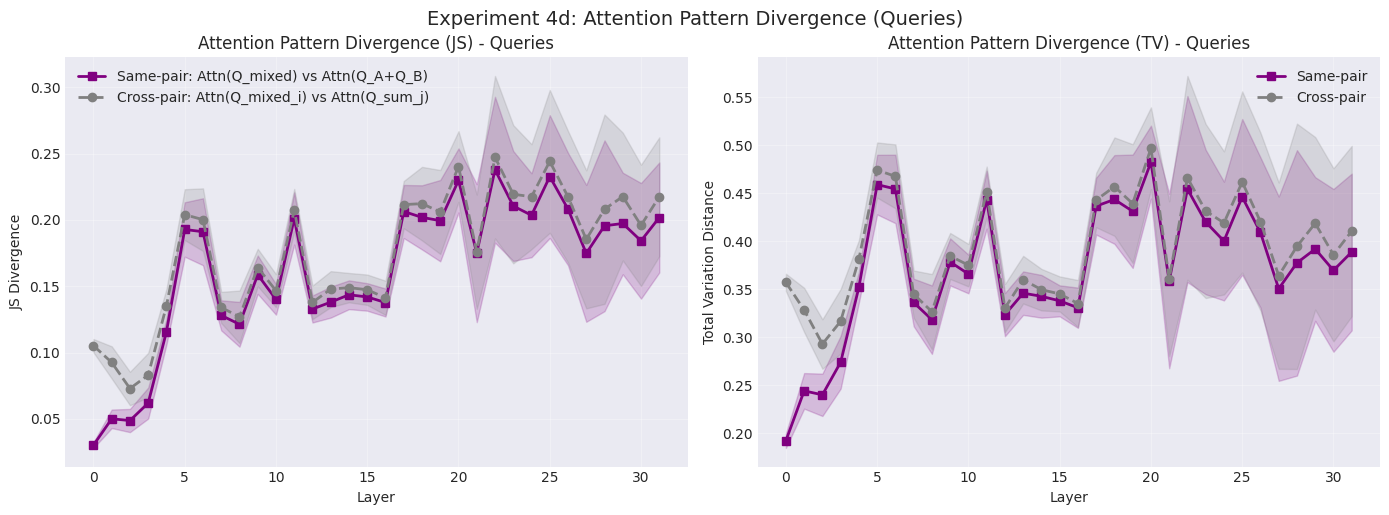


Exp 4d: Attention Pattern Divergence Summary (Queries)

Same-pair: Attn(Q_mixed @ K_mixed) vs Attn((Q_A+Q_B) @ K_mixed)
  JS Divergence: 0.162295 ± 0.025615
  TV Distance:   0.3717 ± 0.0472

Cross-pair: Attn(Q_mixed_i @ K_mixed_i) vs Attn((Q_A_j+Q_B_j) @ K_mixed_i)
  JS Divergence: 0.175396 ± 0.028236
  TV Distance:   0.3933 ± 0.0513

----------------------------------------------------------------------
INTERPRETATION:
  Cross/Same JS ratio: 1.08x
  Cross/Same TV ratio: 1.06x

  [!] Cross-pair divergence is similar to same-pair (1.1x)
      Attention patterns are similar regardless of which Q_sum is used.
      High 'additivity' may be a positional artifact.

----------------------------------------------------------------------
COMPARISON with Experiment 4c (Keys):
  Keys - Cross/Same JS ratio: 1.23x
  Queries - Cross/Same JS ratio: 1.08x

  Both Keys and Queries show similar content-specificity


In [166]:
# Aggregate and visualize attention divergence for Queries
# Extract JS divergence per layer (more interpretable than KL)

same_Q_js_per_layer = np.array([[d['js_div'] for d in pair] for pair in attn_divergence_Q_same])  # [pairs, layers]
same_Q_tv_per_layer = np.array([[d['tv_dist'] for d in pair] for pair in attn_divergence_Q_same])

cross_Q_js_per_layer = np.array([[d['js_div'] for d in pair] for pair in attn_divergence_Q_cross])  # [comparisons, layers]
cross_Q_tv_per_layer = np.array([[d['tv_dist'] for d in pair] for pair in attn_divergence_Q_cross])

# Mean and std across pairs/comparisons
same_Q_js_mean = same_Q_js_per_layer.mean(axis=0)
same_Q_js_std = same_Q_js_per_layer.std(axis=0)
same_Q_tv_mean = same_Q_tv_per_layer.mean(axis=0)
same_Q_tv_std = same_Q_tv_per_layer.std(axis=0)

cross_Q_js_mean = cross_Q_js_per_layer.mean(axis=0)
cross_Q_js_std = cross_Q_js_per_layer.std(axis=0)
cross_Q_tv_mean = cross_Q_tv_per_layer.mean(axis=0)
cross_Q_tv_std = cross_Q_tv_per_layer.std(axis=0)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
layers = range(num_layers)

# Plot 1: JS Divergence
ax = axes[0]
ax.plot(layers, same_Q_js_mean, 's-', label='Same-pair: Attn(Q_mixed) vs Attn(Q_A+Q_B)', color='purple', linewidth=2)
ax.fill_between(layers, same_Q_js_mean - same_Q_js_std, same_Q_js_mean + same_Q_js_std, alpha=0.2, color='purple')
ax.plot(layers, cross_Q_js_mean, 'o--', label='Cross-pair: Attn(Q_mixed_i) vs Attn(Q_sum_j)', color='gray', linewidth=2)
ax.fill_between(layers, cross_Q_js_mean - cross_Q_js_std, cross_Q_js_mean + cross_Q_js_std, alpha=0.2, color='gray')
ax.set_xlabel('Layer')
ax.set_ylabel('JS Divergence')
ax.set_title('Attention Pattern Divergence (JS) - Queries')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Total Variation Distance
ax = axes[1]
ax.plot(layers, same_Q_tv_mean, 's-', label='Same-pair', color='purple', linewidth=2)
ax.fill_between(layers, same_Q_tv_mean - same_Q_tv_std, same_Q_tv_mean + same_Q_tv_std, alpha=0.2, color='purple')
ax.plot(layers, cross_Q_tv_mean, 'o--', label='Cross-pair', color='gray', linewidth=2)
ax.fill_between(layers, cross_Q_tv_mean - cross_Q_tv_std, cross_Q_tv_mean + cross_Q_tv_std, alpha=0.2, color='gray')
ax.set_xlabel('Layer')
ax.set_ylabel('Total Variation Distance')
ax.set_title('Attention Pattern Divergence (TV) - Queries')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.suptitle('Experiment 4d: Attention Pattern Divergence (Queries)', y=1.02, fontsize=14)
plt.savefig('exp4d_attention_divergence_queries.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary
print("\n" + "="*70)
print("Exp 4d: Attention Pattern Divergence Summary (Queries)")
print("="*70)
print(f"\nSame-pair: Attn(Q_mixed @ K_mixed) vs Attn((Q_A+Q_B) @ K_mixed)")
print(f"  JS Divergence: {same_Q_js_mean.mean():.6f} ± {same_Q_js_std.mean():.6f}")
print(f"  TV Distance:   {same_Q_tv_mean.mean():.4f} ± {same_Q_tv_std.mean():.4f}")

print(f"\nCross-pair: Attn(Q_mixed_i @ K_mixed_i) vs Attn((Q_A_j+Q_B_j) @ K_mixed_i)")
print(f"  JS Divergence: {cross_Q_js_mean.mean():.6f} ± {cross_Q_js_std.mean():.6f}")
print(f"  TV Distance:   {cross_Q_tv_mean.mean():.4f} ± {cross_Q_tv_std.mean():.4f}")

print("\n" + "-"*70)
print("INTERPRETATION:")
ratio_Q_js = cross_Q_js_mean.mean() / (same_Q_js_mean.mean() + 1e-10)
ratio_Q_tv = cross_Q_tv_mean.mean() / (same_Q_tv_mean.mean() + 1e-10)
print(f"  Cross/Same JS ratio: {ratio_Q_js:.2f}x")
print(f"  Cross/Same TV ratio: {ratio_Q_tv:.2f}x")

if ratio_Q_js > 2:
    print(f"\n  [✓] Cross-pair divergence is {ratio_Q_js:.1f}x higher than same-pair!")
    print("      Q_mixed genuinely approximates (Q_A + Q_B) for the SAME pair.")
    print("      The additivity is content-specific, not just positional.")
elif ratio_Q_js > 1.2:
    print(f"\n  [~] Cross-pair divergence is somewhat higher ({ratio_Q_js:.1f}x)")
    print("      Some content-specificity exists, but effect is moderate.")
else:
    print(f"\n  [!] Cross-pair divergence is similar to same-pair ({ratio_Q_js:.1f}x)")
    print("      Attention patterns are similar regardless of which Q_sum is used.")
    print("      High 'additivity' may be a positional artifact.")

# Compare with Keys (Exp 4c)
print("\n" + "-"*70)
print("COMPARISON with Experiment 4c (Keys):")
print(f"  Keys - Cross/Same JS ratio: {ratio_js:.2f}x")
print(f"  Queries - Cross/Same JS ratio: {ratio_Q_js:.2f}x")

if ratio_Q_js > ratio_js:
    print(f"\n  Queries show STRONGER content-specificity than Keys ({ratio_Q_js:.2f}x vs {ratio_js:.2f}x)")
elif ratio_Q_js < ratio_js * 0.8:
    print(f"\n  Keys show STRONGER content-specificity than Queries ({ratio_js:.2f}x vs {ratio_Q_js:.2f}x)")
else:
    print(f"\n  Both Keys and Queries show similar content-specificity")